In [1]:
import matplotlib.pyplot as plt
import os
import pandas as pd
import numpy as np
import geopandas as gpd


LOADING FLOW | SINGLE OBJECTIVE
Reading: Furey | HBV_capillary | flow | Single

LOADING FLOW | MULTI OBJECTIVE
Reading: Furey | HBV_capillary | flow | Multi

LOADING BASEFLOW | SINGLE OBJECTIVE
Reading: Furey | HBV_capillary | baseflow | Single

LOADING BASEFLOW | MULTI OBJECTIVE
Reading: Furey | HBV_capillary | baseflow | Multi

FINAL NSE SUMMARY
Flow - Single            : N =   531, Median = 0.6214, Mean = 0.3388
Flow - Multi             : N =   531, Median = 0.6349, Mean = 0.3477
Baseflow - Single        : N =   531, Median = 0.3803, Mean = -0.0348
Baseflow - Multi         : N =   531, Median = 0.6210, Mean = -0.0067


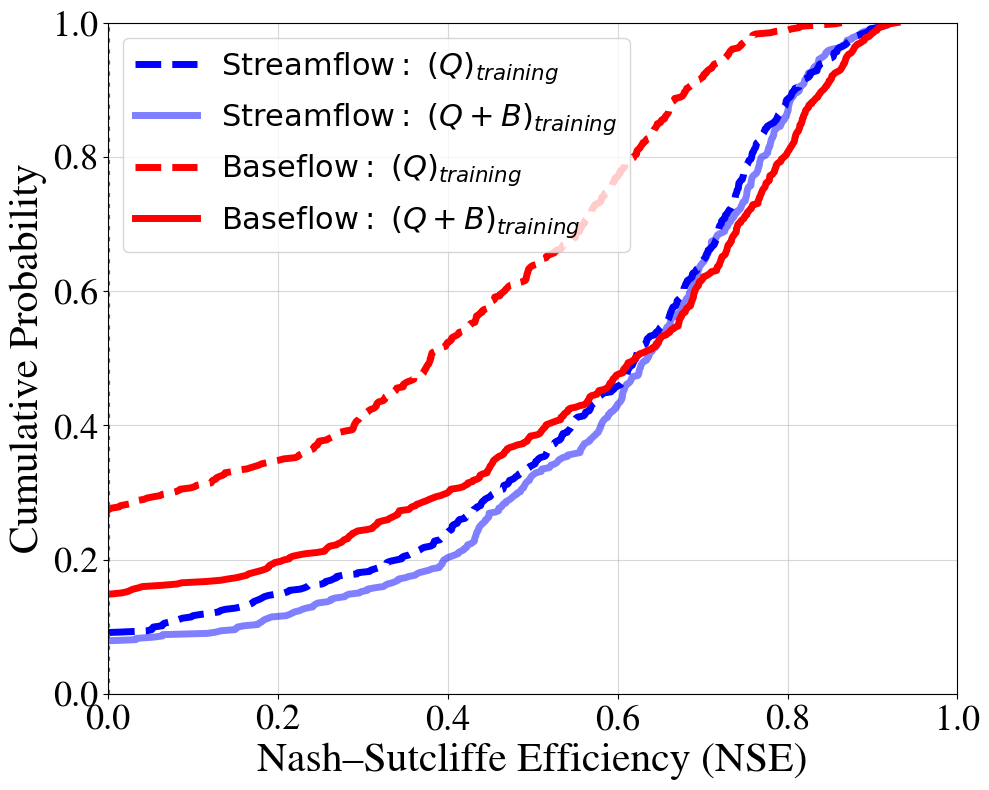

In [3]:
## NSE CDF for HBV_GW2SM and Furey
import numpy as np
import os
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Nimbus Roman'


# ============================================================
# SETTINGS
# ============================================================
test= 'PUR'
methods = [
    # 'USGS',
    'Furey',
    'Eckhardt',
    'LocalHYSEP'
]

methods= ['Furey']

models = [
    'HBV',
    'HBV_capillary',
    'marrmot_PRMS'
]

models= ['HBV_capillary']

fold_numbers = range(1, 8)


# ============================================================
# PUB BASE DIRECTORY
# ============================================================

BASE_DIR = (
    "/home/s0shar47/scratch/"
    f"OUTPUTS_Paper1v2/{test}"
)


# ============================================================
# DYNAMIC PARAMETER FOLDER
# ============================================================

def get_dyn(model):

    if model == 'HBV':
        return 'parBETA_parBETAET_'

    elif model == 'HBV_capillary':
        return 'parBETA_parBETAET_parK0_parUZL_'

    elif model == 'marrmot_PRMS':
        return 'alpha_cgw_scx_tt_'

    else:
        raise ValueError(
            f"Unknown model: {model}"
        )


# ============================================================
# NSE
# ============================================================

def calc_nse(obs, sim):

    mask = (
        np.isfinite(obs)
        &
        np.isfinite(sim)
    )

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    denominator = np.sum(
        (obs - np.mean(obs)) ** 2
    )

    if denominator == 0:
        return np.nan

    numerator = np.sum(
        (obs - sim) ** 2
    )

    return 1 - numerator / denominator


# ============================================================
# GET NSE
#
# component:
#     flow
#     baseflow
#
# objective:
#     Single
#     Multi
# ============================================================

def get_all_nse(component, objective):

    all_nse = []

    print("\n" + "=" * 80)
    print(
        f"LOADING {component.upper()} | "
        f"{objective.upper()} OBJECTIVE"
    )
    print("=" * 80)

    # ========================================================
    # LOOP METHODS
    # ========================================================

    for method in methods:

        # ====================================================
        # LOOP MODELS
        # ====================================================

        for model in models:

            dyn = get_dyn(model)

            print(
                f"Reading: {method} | "
                f"{model} | "
                f"{component} | "
                f"{objective}"
            )

            # =================================================
            # LOOP 10 PUB FOLDS
            # =================================================

            for fold in fold_numbers:

                region = f'Region_{fold}'

                # ====================================================
                # FOLDER DEFINITIONS
                # ====================================================

                single_folder = os.path.join(
                    "/home/s0shar47/scratch/"
                        f"OUTPUTS_Paper1/{test}/"
                    f"OUTPUTS_{test}_Single",
                    region
                )

                multi_folder = os.path.join(
                    BASE_DIR,
                    f"{method}_Multi/NSE/{model}",
                    region
                )


                # ====================================================
                # SIMULATION FOLDER
                # ====================================================

                if objective == 'Single':

                    simulation_folder = (
                        single_folder
                    )

                elif objective == 'Multi':

                    simulation_folder = (
                        multi_folder
                    )

                else:

                    raise ValueError(
                        f"Unknown objective: {objective}"
                    )


                # ====================================================
                # RUN FOLDER
                # ====================================================

                run_folder = (
                    f"LSTM_{model}_E50_R365_B100_H256_"
                    f"tr1989_1999_n16_111111"
                )


                # ====================================================
                # BASE RUN DIRECTORY
                # ====================================================

                run_dir = os.path.join(
                    run_folder,
                    dyn,
                    "ts1989_1999"
                )


                # ====================================================
                # FLOW
                # ====================================================

                if component == 'flow':

                    obs_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "00060_Mean.npy"
                    )

                    sim_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "flow_sim.npy"
                    )


                # ====================================================
                # BASEFLOW
                # ====================================================

                elif component == 'baseflow':

                    # ------------------------------------------------
                    # IMPORTANT:
                    #
                    # Observed baseflow ALWAYS comes from Multi
                    # because Single does not contain baseflow.npy.
                    # ------------------------------------------------

                    obs_file = os.path.join(
                        multi_folder,
                        run_dir,
                        "baseflow.npy"
                    )

                    # ------------------------------------------------
                    # Simulated groundwater flow depends on objective
                    # ------------------------------------------------

                    sim_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "gwflow.npy"
                    )


                else:

                    raise ValueError(
                        f"Unknown component: {component}"
                    )


                # ====================================================
                # CHECK FILES
                # ====================================================

                if not os.path.exists(obs_file):

                    print(
                        f"  Missing OBS: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  --> {obs_file}"
                    )

                    continue


                if not os.path.exists(sim_file):

                    print(
                        f"  Missing SIM: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  --> {sim_file}"
                    )

                    continue


                # ====================================================
                # LOAD
                # ====================================================

                obs = np.load(obs_file)
                sim = np.load(sim_file)

                obs = np.squeeze(obs)
                sim = np.squeeze(sim)


                # ====================================================
                # SHAPE CHECK
                # ====================================================

                if obs.shape != sim.shape:

                    print(
                        f"  Shape mismatch: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  OBS shape = {obs.shape}"
                    )

                    print(
                        f"  SIM shape = {sim.shape}"
                    )

                    continue


                # ====================================================
                # BASIN-WISE NSE
                # ====================================================

                for basin in range(
                    obs.shape[1]
                ):

                    obs_basin = obs[:, basin]

                    sim_basin = sim[:, basin]

                    nse = calc_nse(
                        obs_basin,
                        sim_basin
                    )

                    if np.isfinite(nse):

                        all_nse.append(nse)


    return np.asarray(
        all_nse,
        dtype=float
    )


# ============================================================
# LOAD FLOW
# ============================================================

nse_flow_single = get_all_nse(
    component='flow',
    objective='Single'
)

nse_flow_multi = get_all_nse(
    component='flow',
    objective='Multi'
)


# ============================================================
# LOAD BASEFLOW
# ============================================================

nse_baseflow_single = get_all_nse(
    component='baseflow',
    objective='Single'
)

nse_baseflow_multi = get_all_nse(
    component='baseflow',
    objective='Multi'
)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL NSE SUMMARY")
print("=" * 80)

def print_summary(name, values):

    if len(values) == 0:

        print(
            f"{name:25s}: N = 0"
        )

    else:

        print(
            f"{name:25s}: "
            f"N = {len(values):5d}, "
            f"Median = {np.median(values):.4f}, "
            f"Mean = {np.mean(values):.4f}"
        )


print_summary(
    "Flow - Single",
    nse_flow_single
)

print_summary(
    "Flow - Multi",
    nse_flow_multi
)

print_summary(
    "Baseflow - Single",
    nse_baseflow_single
)

print_summary(
    "Baseflow - Multi",
    nse_baseflow_multi
)


# ============================================================
# EMPIRICAL CDF
# ============================================================

def empirical_cdf(values):

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:

        return (
            np.array([]),
            np.array([])
        )

    values = np.sort(values)

    y = (
        np.arange(1, len(values) + 1)
        / len(values)
    )

    return values, y


# ============================================================
# CDFS
# ============================================================

x_flow_single, y_flow_single = empirical_cdf(
    nse_flow_single
)

x_flow_multi, y_flow_multi = empirical_cdf(
    nse_flow_multi
)

x_baseflow_single, y_baseflow_single = empirical_cdf(
    nse_baseflow_single
)

x_baseflow_multi, y_baseflow_multi = empirical_cdf(
    nse_baseflow_multi
)


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)


# ------------------------------------------------------------
# FLOW — SINGLE
# ------------------------------------------------------------

if len(x_flow_single) > 0:

    plt.plot(
        x_flow_single,
        y_flow_single,
        linewidth=5,
        linestyle='--',
        label=r'$\mathrm{Streamflow:}\ (Q)_{\mathit{training}}$'
        ,color= 'blue'
    )


# ------------------------------------------------------------
# FLOW — MULTI
# ------------------------------------------------------------

if len(x_flow_multi) > 0:

    plt.plot(
        x_flow_multi,
        y_flow_multi,
        linewidth=5,
        linestyle='-',
        label= r'$\mathrm{Streamflow:}\ (Q+B)_{\mathit{training}}$'
        ,color= 'blue',
        alpha=0.5
    )


# ------------------------------------------------------------
# BASEFLOW — SINGLE
# ------------------------------------------------------------

if len(x_baseflow_single) > 0:

    plt.plot(
        x_baseflow_single,
        y_baseflow_single,
        linewidth=5,
        linestyle='--',
        label= r'$\mathrm{Baseflow:}\ (Q)_{\mathit{training}}$'
        ,color= 'red'
    )


# ------------------------------------------------------------
# BASEFLOW — MULTI
# ------------------------------------------------------------

if len(x_baseflow_multi) > 0:

    plt.plot(
        x_baseflow_multi,
        y_baseflow_multi,
        linewidth=5,
        linestyle='-',
        label= r'$\mathrm{Baseflow:}\ (Q+B)_{\mathit{training}}$'
        ,color= 'red'
    )


# ============================================================
# NSE = 0
# ============================================================

plt.axvline(
    x=0,
    linestyle=':',
    linewidth=3
)


# ============================================================
# AXES
# ============================================================

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)


# ============================================================
# LABELS
# ============================================================

plt.xlabel(
    'Nash–Sutcliffe Efficiency (NSE)',
    fontsize=30
)

plt.ylabel(
    'Cumulative Probability',
    fontsize=30
)


# ============================================================
# TITLE
# ============================================================

# plt.title(
#     f'{test} TEST: NSE CDF',
#     fontsize=32
# )


# ============================================================
# TICKS
# ============================================================

plt.xticks(
    fontsize=26
)

plt.yticks(
    fontsize=26
)


# ============================================================
# GRID
# ============================================================

plt.grid(
    True,
    alpha=0.5
)


# ============================================================
# LEGEND
# ============================================================

plt.legend(
    fontsize=22,
    frameon=True,
    loc='upper left'
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# SHOW
# ============================================================
plt.savefig("/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures/NSE_CDF_HBVcapFurey.jpg", dpi= 400)
plt.show()

HUC2 CRS before assignment: None
HUC2 bounds before transformation:
[-7783576.02289802  2187575.63815253  3619690.05690435 10257816.27458091]
HUC2 CRS after assignment: EPSG:26915
HUC2 CRS after transformation: EPSG:4326
HUC2 bounds after transformation:
[-179.96928239   17.67456073  179.91556688   71.39676244]

HUC2 columns:
['HUC2', 'COUNT', 'REG_NAME', 'ACRES', 'geometry']

Using HUC2 column: HUC2

HUC2 codes found:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']

The following HUC2 regions were not assigned:
['19', '20', '21']

PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.2193

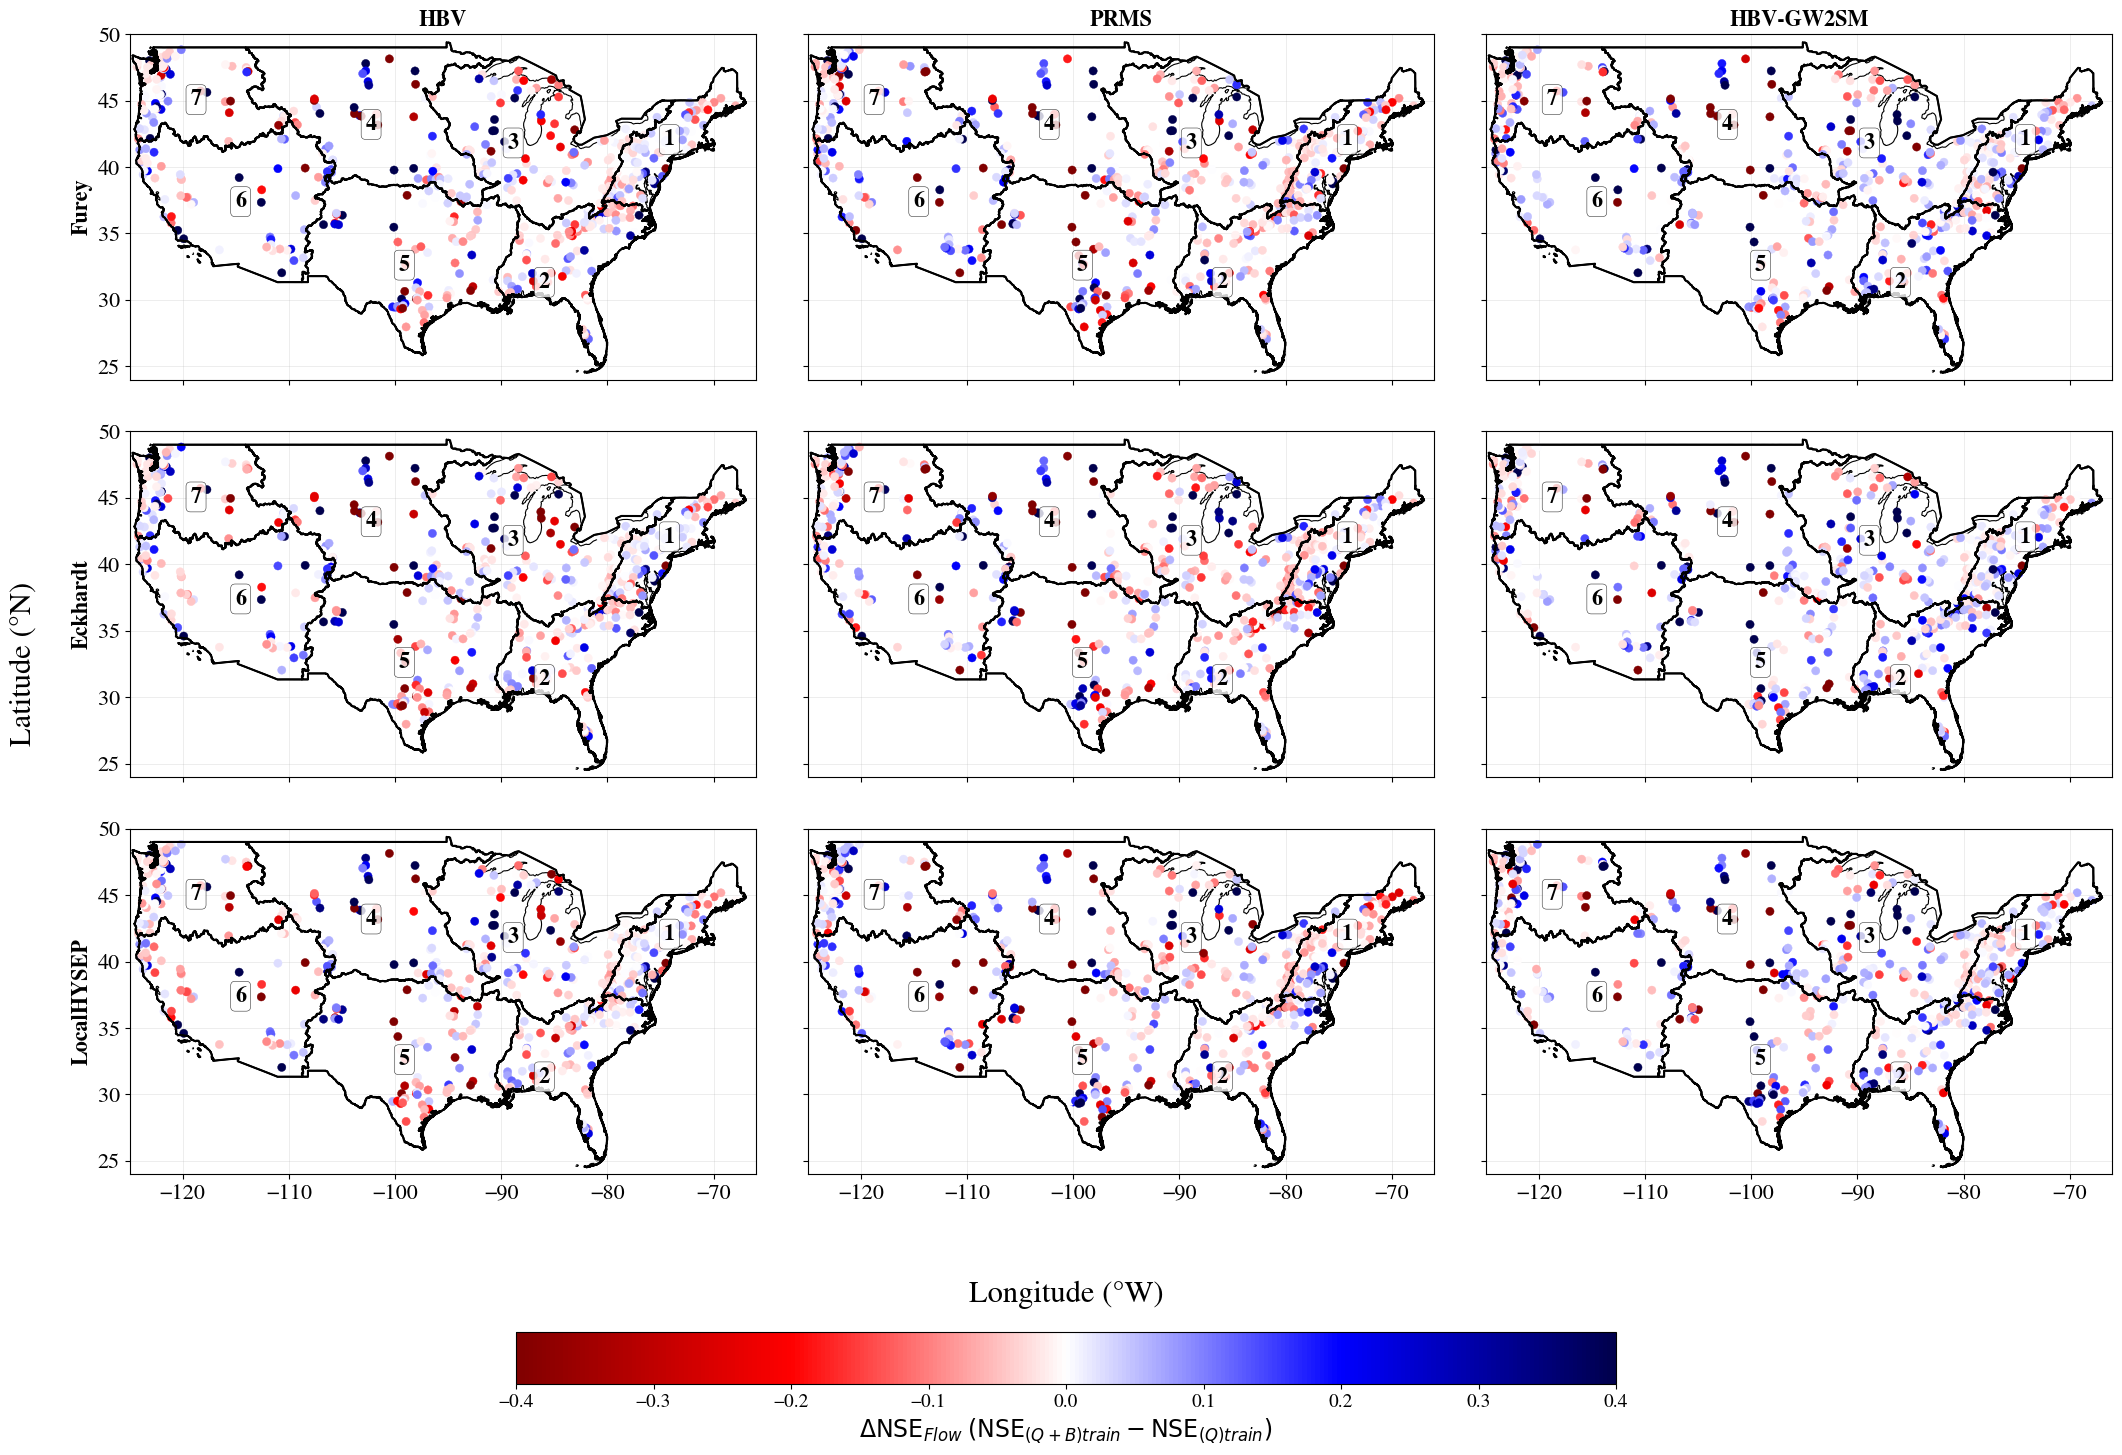

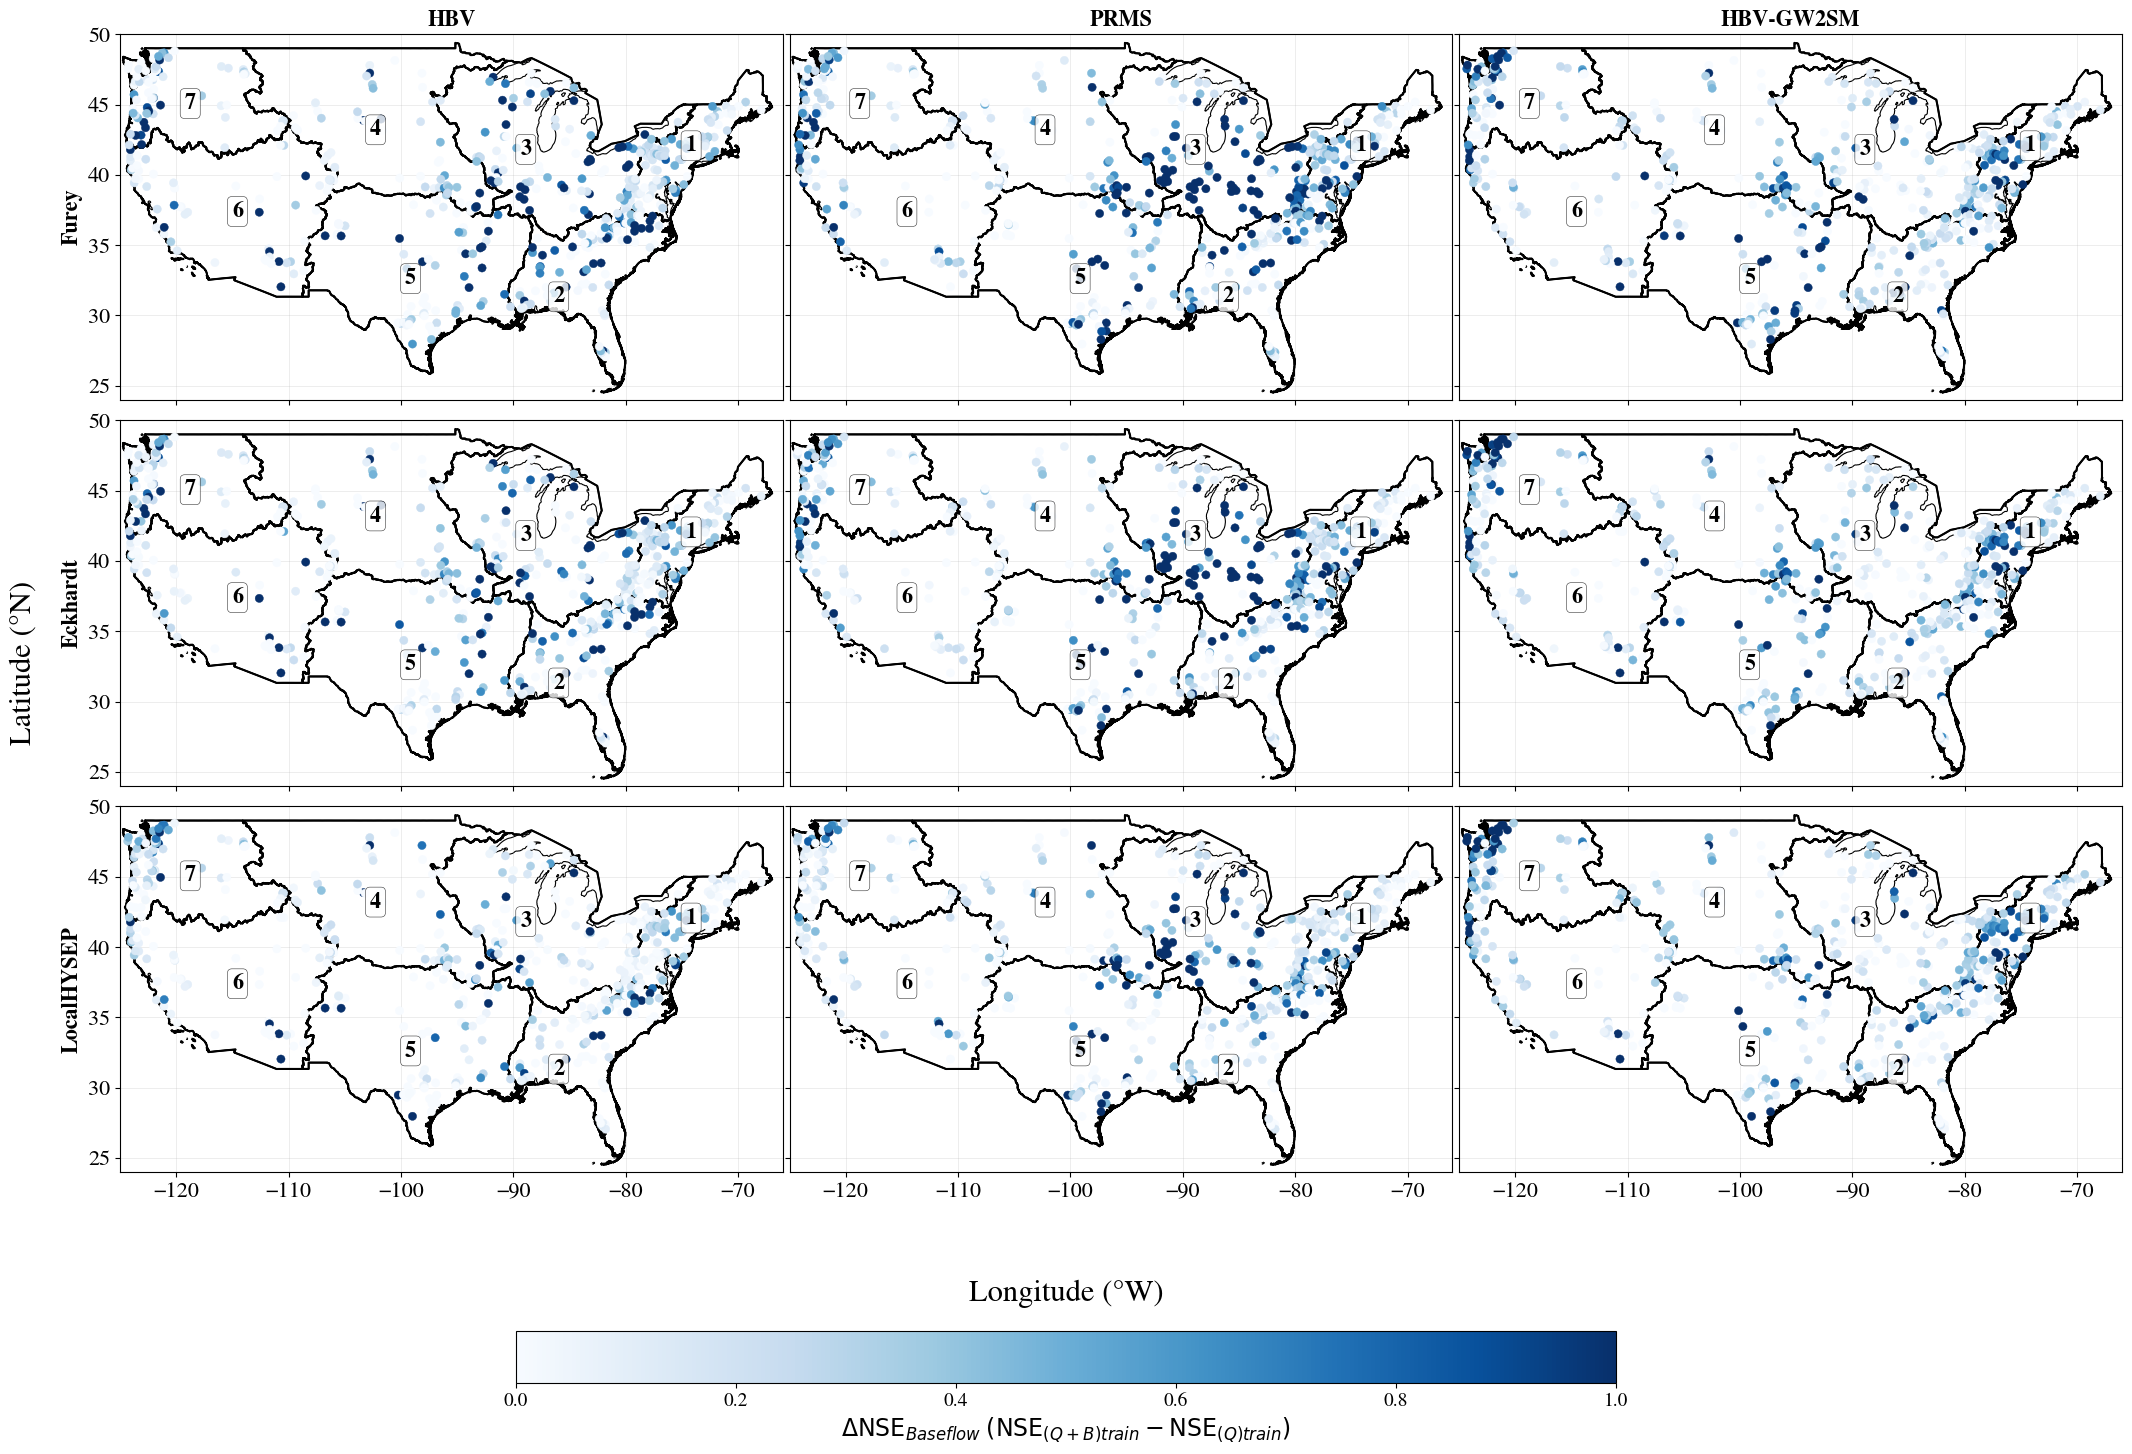

In [5]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box


loss= 'NSE'
# ============================================================
# FUNCTION TO PLOT PUR REGIONS AND REGION NUMBERS
# ============================================================

def add_pur_regions(ax, gdf_pur_regions):

    # Plot PUR region boundaries
    gdf_pur_regions.boundary.plot(
        ax=ax,
        edgecolor="black",
        linewidth=1.5,
        zorder=3
    )

    # Add region numbers
    for _, row in gdf_pur_regions.iterrows():

        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"{int(row['PUR_region'])}",
            fontsize=16,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )


plt.rcParams['font.family']= 'Nimbus Roman'

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)


# ============================================================
# PUR REGION DEFINITION FROM FENG ET AL.
# ============================================================

pur_groups = {
    1: ['01', '02'],
    2: ['03', '06'],
    3: ['04', '05', '07'],
    4: ['09', '10'],
    5: ['08', '11', '12', '13'],
    6: ['14', '15', '16', '18'],
    7: ['17']
}

# [ [1,2], [3,6], [4,5,7], [9,10], [8,11,12,13], [14,15,16,18], [17] ]

# ------------------------------------------------------------
# Make sure HUC2 codes are strings with leading zero
# ------------------------------------------------------------

gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")

print("HUC2 CRS before assignment:", gdf_huc2.crs)
print("HUC2 bounds before transformation:")
print(gdf_huc2.total_bounds)
gdf_huc2 = gdf_huc2.set_crs(
    "EPSG:26915"
)

print("HUC2 CRS after assignment:", gdf_huc2.crs)


# ============================================================
# TRANSFORM HUC2 TO WGS84
# ============================================================

gdf_huc2 = gdf_huc2.to_crs(
    "EPSG:4326"
)

print("HUC2 CRS after transformation:", gdf_huc2.crs)
print("HUC2 bounds after transformation:")
print(gdf_huc2.total_bounds)


# ============================================================
# CHECK HUC2 COLUMNS
# ============================================================

print("\nHUC2 columns:")
print(gdf_huc2.columns.tolist())


possible_huc_columns = [
    "HUC2",
    "HUC_2",
    "HUC2_CODE",
    "HUC_02",
    "HUC_02_",
    "HUC2_",
    "HUC"
]

huc_column = None

for col in possible_huc_columns:

    if col in gdf_huc2.columns:
        huc_column = col
        break

if huc_column is None:

    raise ValueError(
        "\nCould not identify the HUC2 column.\n"
        "Available columns are:\n"
        + str(gdf_huc2.columns.tolist())
    )

print("\nUsing HUC2 column:", huc_column)


# ============================================================
# STANDARDIZE HUC2 CODES
# ============================================================

gdf_huc2["HUC2_CODE"] = (
    gdf_huc2[huc_column]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

print("\nHUC2 codes found:")
print(
    sorted(
        gdf_huc2["HUC2_CODE"].unique()
    )
)


# ============================================================
# CREATE HUC2 -> PUR REGION LOOKUP
# ============================================================

huc_to_region = {}

for region, hucs in pur_groups.items():

    for huc in hucs:

        huc_to_region[huc] = region


# ============================================================
# ASSIGN PUR REGION
# ============================================================

gdf_huc2["PUR_region"] = (
    gdf_huc2["HUC2_CODE"]
    .map(huc_to_region)
)


# Check whether any HUC2 was not assigned
unassigned = gdf_huc2[
    gdf_huc2["PUR_region"].isna()
]

if len(unassigned) > 0:

    print("\nWARNING:")
    print("The following HUC2 regions were not assigned:")
    print(
        unassigned["HUC2_CODE"]
        .tolist()
    )


# ============================================================
# KEEP PUR REGIONS
# ============================================================

gdf_pur = gdf_huc2.dropna(
    subset=["PUR_region"]
).copy()

gdf_pur["PUR_region"] = (
    gdf_pur["PUR_region"]
    .astype(int)
)


# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)


# ============================================================
# CREATE BASIN POINTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING BASIN POINTS")
print("=" * 70)


## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

# ============================================================
# CREATE BOTH 3 x 3 FIGURES BEFORE THE LOOPS
# ============================================================

fig_flow, axes_flow = plt.subplots(
    3, 3,
    figsize=(22, 15),
    sharex=True,
    sharey=True
)

fig_baseflow, axes_baseflow = plt.subplots(
    3, 3,
    figsize=(22, 15),
    sharex=True,
    sharey=True
)


# Keep scatter objects so we can create shared colorbars later
scatter_flow = None
scatter_baseflow = None


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================


for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)


        ax = axes_flow[i, j]

        # CONUS boundary
        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )

        # --------------------------------------------
        # Delta Flow NSE
        # --------------------------------------------

        delta_flow_nse = (
            table['NSE-Flow (Multi-Objective)']
            - table['NSE-Flow (Single-Objective)']
        )

        scatter_flow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_flow_nse,
            cmap='seismic_r',
            vmin=-0.4,
            vmax=0.4,
            linewidth=0.3,
            zorder=2
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        gdf_pur_regions.boundary.plot(
                    ax=ax,
                    edgecolor="black",
                    linewidth=1.2,
                    zorder=3
                )
        if i == 0:
            # --------------------------------------------
            # Subplot title
            # --------------------------------------------
            ax.set_title(
                            f"{model_name}",
                            fontsize=16,
                            fontweight='bold'
                        )
            # ax.set_title(
            #     f"{method} | {model_name}",
            #     fontsize=13,
            #     fontweight='bold'
            # )

        if j== 0:

            ax.set_ylabel(f"{method}",
                            fontsize=16,
                            fontweight='bold')



        # --------------------------------------------
        # Map limits
        # --------------------------------------------

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        # --------------------------------------------
        # Grid
        # --------------------------------------------

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )


        # ====================================================
        # FIGURE 2:
        # DELTA BASEFLOW NSE
        # ====================================================

        ax = axes_baseflow[i, j]

        # --------------------------------------------
        # CONUS boundary
        # --------------------------------------------

        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        # --------------------------------------------
        # PUR Region boundaries
        # --------------------------------------------

        gdf_pur_regions.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=1.2,
            zorder=3
        )

        # --------------------------------------------
        # Delta Baseflow NSE
        # --------------------------------------------

        delta_baseflow_nse = (
            table['NSE-Baseflow (Multi-Objective)']
            - table['NSE-Baseflow (Single-Objective)']
        )

        scatter_baseflow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_baseflow_nse,
            cmap='Blues',
            vmin=0,
            vmax=1,
            linewidth=0.3,
            zorder=4
        )


        # --------------------------------------------
        # Subplot title
        # --------------------------------------------

        # ax.set_title(
        #     f"{method} | {model}",
        #     fontsize=13,
        #     fontweight='bold'
        # )

        # --------------------------------------------
        # Map limits
        # --------------------------------------------


        if i == 0:
                    # --------------------------------------------
                    # Subplot title
                    # --------------------------------------------
                    ax.set_title(
                                    f"{model_name}",
                                    fontsize=16,
                                    fontweight='bold'
                                )
                    # ax.set_title(
                    #     f"{method} | {model_name}",
                    #     fontsize=13,
                    #     fontweight='bold'
                    # )
        
        if j== 0:
        
                    ax.set_ylabel(f"{method}",
                                    fontsize=16,
                                    fontweight='bold')
        

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )

        print(i, j, method, model)


# ============================================================
# FIGURE 1 FORMATTING
# DELTA FLOW NSE
# ============================================================

# fig_flow.suptitle(
#     "Change in Streamflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


# ------------------------------------------------------------
# Shared X/Y labels
# ------------------------------------------------------------

fig_flow.supxlabel(
    "Longitude (°W)",
    fontsize=22,
    y=0.07
)

fig_flow.supylabel(
    "Latitude (°N)",
    fontsize=22,
    x=0.02
)


# ------------------------------------------------------------
# Make room for colorbar
# ------------------------------------------------------------

fig_flow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_flow = fig_flow.add_axes([
    0.25,   # left
    0.02,   # bottom
    0.50,   # width
    0.035   # height
])

cbar_flow = fig_flow.colorbar(
    scatter_flow,
    cax=cbar_ax_flow,
    orientation='horizontal'
)

cbar_flow.set_label(
    r'$\Delta \mathrm{NSE}_{Flow}$ '
    r'$(\mathrm{NSE}_{(Q+B)train} - \mathrm{NSE}_{(Q)train})$',
    fontsize=17
)

cbar_flow.ax.tick_params(
    labelsize=14
)


# ============================================================
# FIGURE 2 FORMATTING
# DELTA BASEFLOW NSE
# ============================================================

# fig_baseflow.suptitle(
#     "Change in Baseflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


fig_baseflow.supxlabel(
    "Longitude (°W)",
    fontsize=22,
    y=0.07
)

fig_baseflow.supylabel(
    "Latitude (°N)",
    fontsize=22,
    x=0.02
)


fig_baseflow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.01,
    hspace=0.05
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_baseflow = fig_baseflow.add_axes([
    0.25,
    0.02,
    0.50,
    0.035
])

cbar_baseflow = fig_baseflow.colorbar(
    scatter_baseflow,
    cax=cbar_ax_baseflow,
    orientation='horizontal'
)

cbar_baseflow.set_label(
    r'$\Delta \mathrm{NSE}_{Baseflow}$ '
    r'$(\mathrm{NSE}_{(Q+B)train} - \mathrm{NSE}_{(Q)train})$',
    fontsize=17
)

cbar_baseflow.ax.tick_params(
    labelsize=14
)

output_dir = "/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures/"

########################################################################
fig_flow.savefig(
    f"{output_dir}/Delta_Flow_NSE_3x3.jpg",
    dpi=400,
    bbox_inches="tight"
)

########################################################################
fig_baseflow.savefig(
    f"{output_dir}/Delta_Baseflow_NSE_3x3.jpg",
    dpi=400,
    bbox_inches="tight"
)
# ============================================================
# SHOW ONLY AFTER ALL 9 SUBPLOTS HAVE BEEN CREATED
# ============================================================
plt.show()

HUC2 CRS before assignment: None
HUC2 bounds before transformation:
[-7783576.02289802  2187575.63815253  3619690.05690435 10257816.27458091]
HUC2 CRS after assignment: EPSG:26915
HUC2 CRS after transformation: EPSG:4326
HUC2 bounds after transformation:
[-179.96928239   17.67456073  179.91556688   71.39676244]

HUC2 columns:
['HUC2', 'COUNT', 'REG_NAME', 'ACRES', 'geometry']

Using HUC2 column: HUC2

HUC2 codes found:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']

The following HUC2 regions were not assigned:
['19', '20', '21']

PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.2193

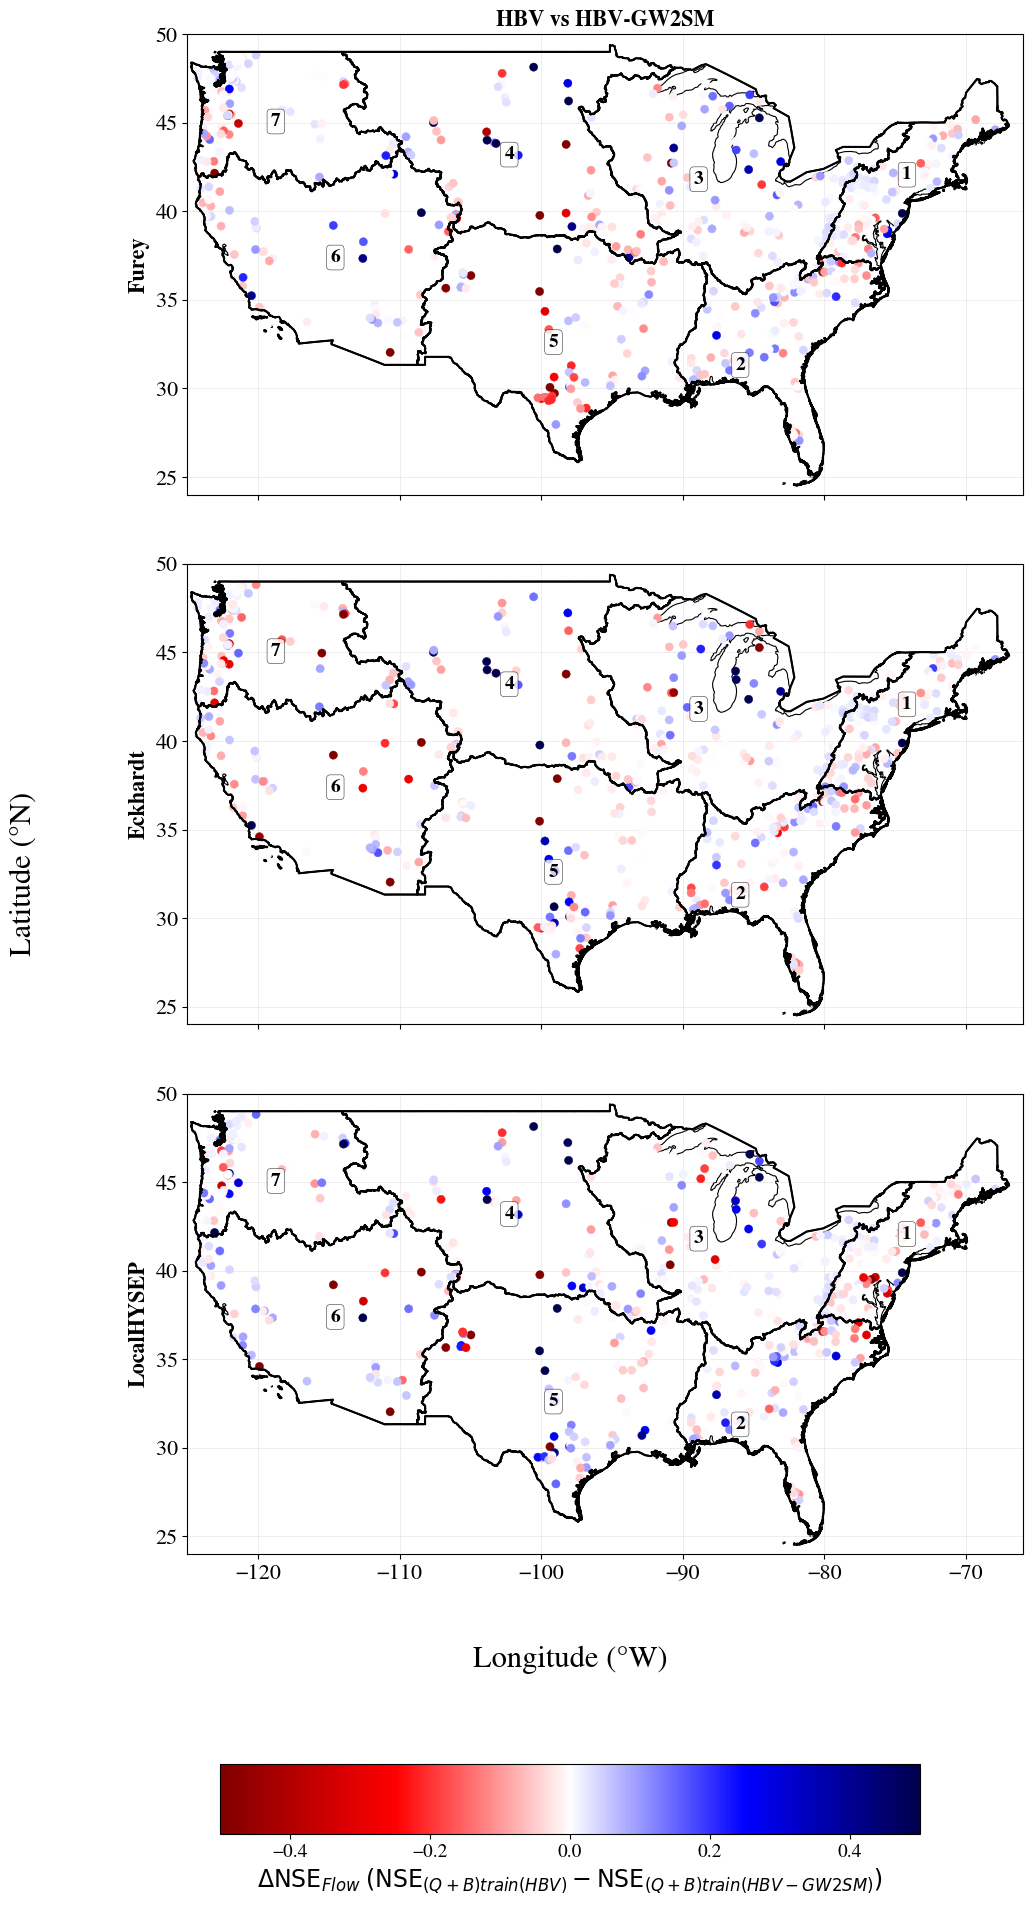

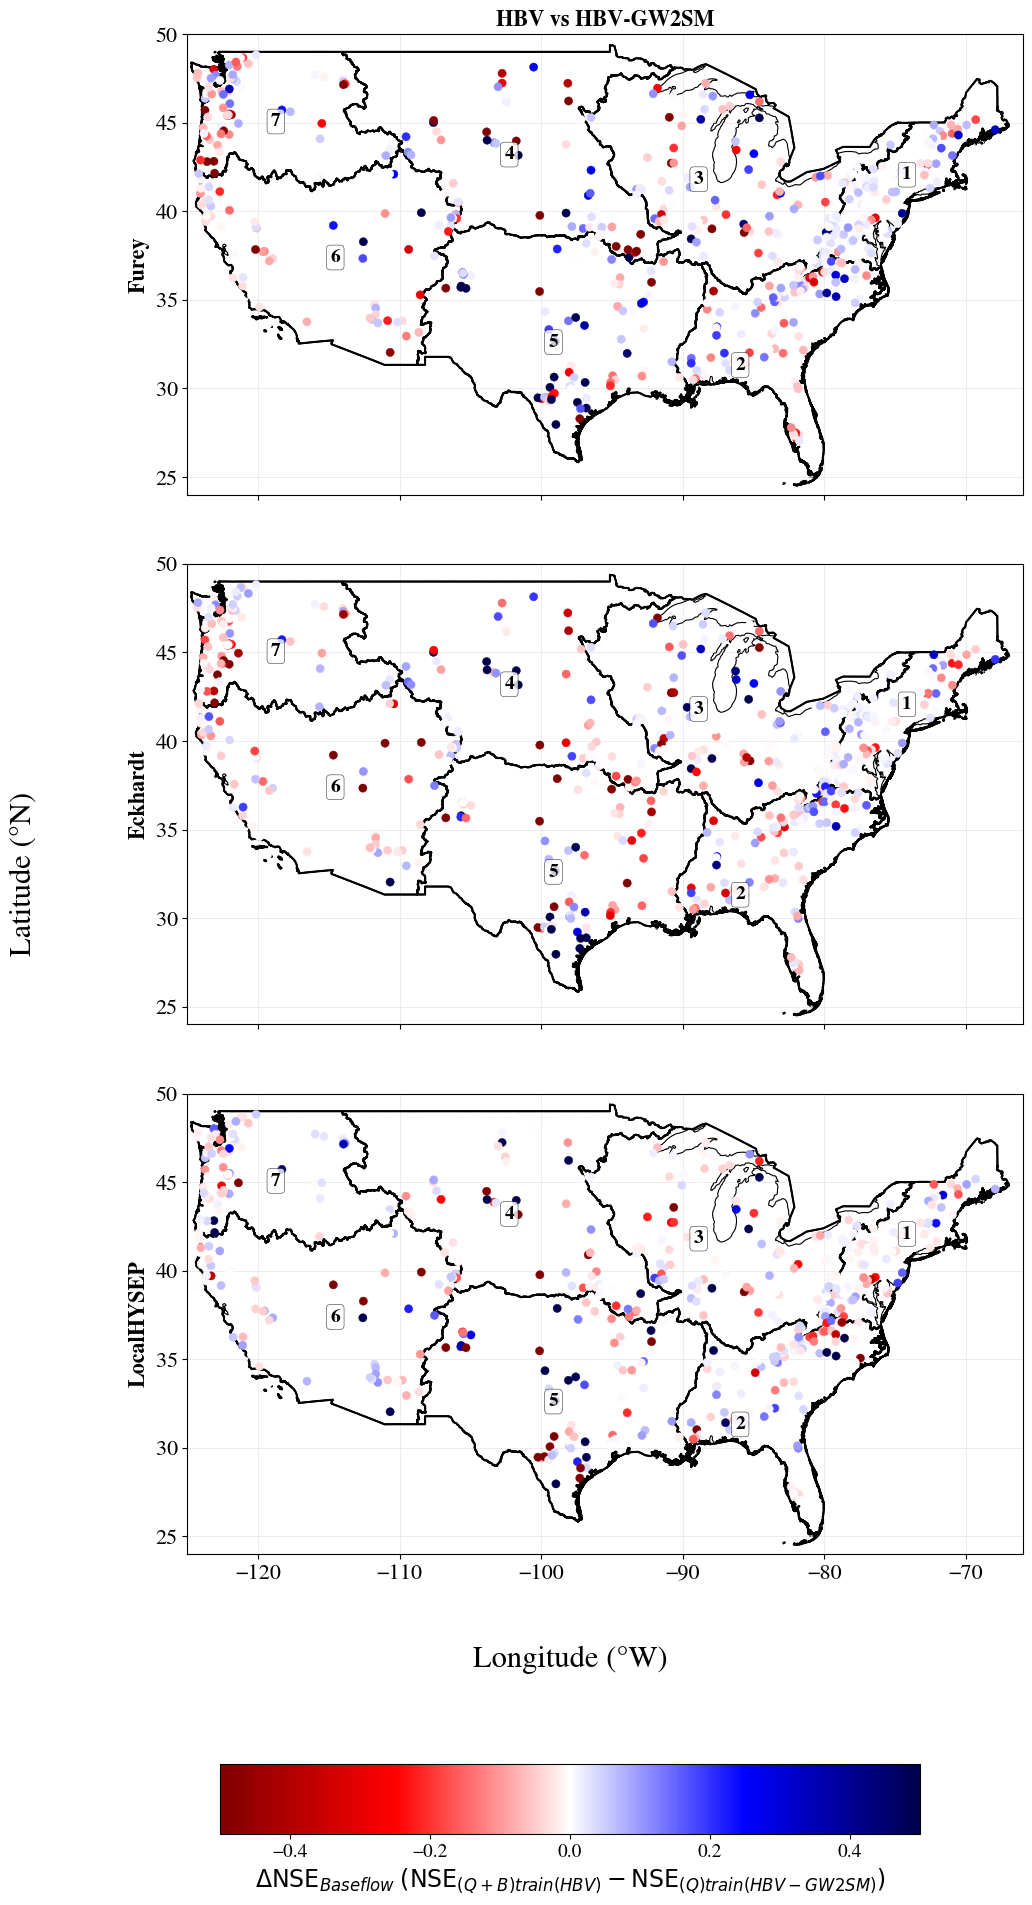

In [31]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# ============================================================
# FUNCTION TO PLOT PUR REGIONS AND REGION NUMBERS
# ============================================================

def add_pur_regions(ax, gdf_pur_regions):

    # Plot PUR region boundaries
    gdf_pur_regions.boundary.plot(
        ax=ax,
        edgecolor="black",
        linewidth=1.5,
        zorder=3
    )

    # Add region numbers
    for _, row in gdf_pur_regions.iterrows():

        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"{int(row['PUR_region'])}",
            fontsize=14,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )


plt.rcParams['font.family']= 'Nimbus Roman'

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)


# ============================================================
# PUR REGION DEFINITION FROM FENG ET AL.
# ============================================================

pur_groups = {
    1: ['01', '02'],
    2: ['03', '06'],
    3: ['04', '05', '07'],
    4: ['09', '10'],
    5: ['08', '11', '12', '13'],
    6: ['14', '15', '16', '18'],
    7: ['17']
}

# [ [1,2], [3,6], [4,5,7], [9,10], [8,11,12,13], [14,15,16,18], [17] ]

# ------------------------------------------------------------
# Make sure HUC2 codes are strings with leading zero
# ------------------------------------------------------------

gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")

print("HUC2 CRS before assignment:", gdf_huc2.crs)
print("HUC2 bounds before transformation:")
print(gdf_huc2.total_bounds)
gdf_huc2 = gdf_huc2.set_crs(
    "EPSG:26915"
)

print("HUC2 CRS after assignment:", gdf_huc2.crs)


# ============================================================
# TRANSFORM HUC2 TO WGS84
# ============================================================

gdf_huc2 = gdf_huc2.to_crs(
    "EPSG:4326"
)

print("HUC2 CRS after transformation:", gdf_huc2.crs)
print("HUC2 bounds after transformation:")
print(gdf_huc2.total_bounds)


# ============================================================
# CHECK HUC2 COLUMNS
# ============================================================

print("\nHUC2 columns:")
print(gdf_huc2.columns.tolist())


possible_huc_columns = [
    "HUC2",
    "HUC_2",
    "HUC2_CODE",
    "HUC_02",
    "HUC_02_",
    "HUC2_",
    "HUC"
]

huc_column = None

for col in possible_huc_columns:

    if col in gdf_huc2.columns:
        huc_column = col
        break

if huc_column is None:

    raise ValueError(
        "\nCould not identify the HUC2 column.\n"
        "Available columns are:\n"
        + str(gdf_huc2.columns.tolist())
    )

print("\nUsing HUC2 column:", huc_column)


# ============================================================
# STANDARDIZE HUC2 CODES
# ============================================================

gdf_huc2["HUC2_CODE"] = (
    gdf_huc2[huc_column]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

print("\nHUC2 codes found:")
print(
    sorted(
        gdf_huc2["HUC2_CODE"].unique()
    )
)


# ============================================================
# CREATE HUC2 -> PUR REGION LOOKUP
# ============================================================

huc_to_region = {}

for region, hucs in pur_groups.items():

    for huc in hucs:

        huc_to_region[huc] = region


# ============================================================
# ASSIGN PUR REGION
# ============================================================

gdf_huc2["PUR_region"] = (
    gdf_huc2["HUC2_CODE"]
    .map(huc_to_region)
)


# Check whether any HUC2 was not assigned
unassigned = gdf_huc2[
    gdf_huc2["PUR_region"].isna()
]

if len(unassigned) > 0:

    print("\nWARNING:")
    print("The following HUC2 regions were not assigned:")
    print(
        unassigned["HUC2_CODE"]
        .tolist()
    )


# ============================================================
# KEEP PUR REGIONS
# ============================================================

gdf_pur = gdf_huc2.dropna(
    subset=["PUR_region"]
).copy()

gdf_pur["PUR_region"] = (
    gdf_pur["PUR_region"]
    .astype(int)
)


# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)


# ============================================================
# CREATE BASIN POINTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING BASIN POINTS")
print("=" * 70)


## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
# models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']
models= ['HBV']



if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

# ============================================================
# CREATE BOTH 3 x 1 FIGURES BEFORE THE LOOPS
# ============================================================

fig_flow, axes_flow = plt.subplots(
    3, 1,
    figsize=(14, 20),
    sharex=True,
    sharey=True
)

fig_baseflow, axes_baseflow = plt.subplots(
    3, 1,
    figsize=(14, 20),
    sharex=True,
    sharey=True
)

scatter_flow = None
scatter_baseflow = None

# ============================================================
# YOUR 3 x 1 LOOPS
# ============================================================


for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/HBV_capillary/{region}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/HBV_capillary/{region}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)


        # ax = axes_flow[i, j]
        ax = axes_flow[i]

        # CONUS boundary
        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )

        # --------------------------------------------
        # Delta Flow NSE
        # --------------------------------------------

        delta_flow_nse = (
            table['NSE-Flow (Multi-Objective)']
            - table['NSE-Flow (Single-Objective)']
        )

        scatter_flow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_flow_nse,
            cmap='seismic_r',
            vmin=-0.5,
            vmax=0.5,
            linewidth=0.3,
            zorder=2
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        gdf_pur_regions.boundary.plot(
                    ax=ax,
                    edgecolor="black",
                    linewidth=1.2,
                    zorder=3
                )
        if i == 0:
            # --------------------------------------------
            # Subplot title
            # --------------------------------------------
            ax.set_title(
                            f"{model_name} vs HBV-GW2SM",
                            fontsize=16,
                            fontweight='bold'
                        )
            # ax.set_title(
            #     f"{method} | {model_name}",
            #     fontsize=13,
            #     fontweight='bold'
            # )

        if j== 0:

            ax.set_ylabel(f"{method}",
                            fontsize=16,
                            fontweight='bold')



        # --------------------------------------------
        # Map limits
        # --------------------------------------------

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        # --------------------------------------------
        # Grid
        # --------------------------------------------

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )


        # ====================================================
        # FIGURE 2:
        # DELTA BASEFLOW NSE
        # ====================================================

        # ax = axes_baseflow[i, j]
        ax = axes_baseflow[i]

        # --------------------------------------------
        # CONUS boundary
        # --------------------------------------------

        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        # --------------------------------------------
        # PUR Region boundaries
        # --------------------------------------------

        gdf_pur_regions.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=1.2,
            zorder=3
        )

        # --------------------------------------------
        # Delta Baseflow NSE
        # --------------------------------------------

        delta_baseflow_nse = (
            table['NSE-Baseflow (Multi-Objective)']
            - table['NSE-Baseflow (Single-Objective)']
        )

        scatter_baseflow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_baseflow_nse,
            cmap='seismic_r',
            vmin=-0.5,
            vmax=0.5,
            linewidth=0.3,
            zorder=4
        )


        # --------------------------------------------
        # Subplot title
        # --------------------------------------------

        # ax.set_title(
        #     f"{method} | {model}",
        #     fontsize=13,
        #     fontweight='bold'
        # )

        # --------------------------------------------
        # Map limits
        # --------------------------------------------


        if i == 0:
                    # --------------------------------------------
                    # Subplot title
                    # --------------------------------------------
                    ax.set_title(
                                    f"{model_name} vs HBV-GW2SM",
                                    fontsize=16,
                                    fontweight='bold'
                                )
                    # ax.set_title(
                    #     f"{method} | {model_name}",
                    #     fontsize=13,
                    #     fontweight='bold'
                    # )
        
        if j== 0:
        
                    ax.set_ylabel(f"{method}",
                                    fontsize=16,
                                    fontweight='bold')
        

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )

        print(i, j, method, model)


# ============================================================
# FIGURE 1 FORMATTING
# DELTA FLOW NSE
# ============================================================

# fig_flow.suptitle(
#     "Change in Streamflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


# ------------------------------------------------------------
# Shared X/Y labels
# ------------------------------------------------------------

fig_flow.supxlabel(
    "Longitude (°W)",
    fontsize=22,
    y=0.1
)

fig_flow.supylabel(
    "Latitude (°N)",
    fontsize=22,
    x=0.1
)


# ------------------------------------------------------------
# Make room for colorbar
# ------------------------------------------------------------

fig_flow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_flow = fig_flow.add_axes([
    0.25,   # left
    0.02,   # bottom
    0.50,   # width
    0.035   # height
])

cbar_flow = fig_flow.colorbar(
    scatter_flow,
    cax=cbar_ax_flow,
    orientation='horizontal'
)

cbar_flow.set_label(
    r'$\Delta \mathrm{NSE}_{Flow}$ '
    r'$(\mathrm{NSE}_{(Q+B)train(HBV)} - \mathrm{NSE}_{(Q+B)train(HBV-GW2SM)})$',
    fontsize=17
)

cbar_flow.ax.tick_params(
    labelsize=14
)


# ============================================================
# FIGURE 2 FORMATTING
# DELTA BASEFLOW NSE
# ============================================================

# fig_baseflow.suptitle(
#     "Change in Baseflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


fig_baseflow.supxlabel(
    "Longitude (°W)",
    fontsize=22,
    y=0.1
)

fig_baseflow.supylabel(
    "Latitude (°N)",
    fontsize=22,
    x=0.1
)


fig_baseflow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_baseflow = fig_baseflow.add_axes([
    0.25,
    0.02,
    0.50,
    0.035
])

cbar_baseflow = fig_baseflow.colorbar(
    scatter_baseflow,
    cax=cbar_ax_baseflow,
    orientation='horizontal'
)

cbar_baseflow.set_label(
    r'$\Delta \mathrm{NSE}_{Baseflow}$ '
    r'$(\mathrm{NSE}_{(Q+B)train(HBV)} - \mathrm{NSE}_{(Q)train(HBV-GW2SM)})$',
    fontsize=17
)

cbar_baseflow.ax.tick_params(
    labelsize=14
)


# ============================================================
# SHOW ONLY AFTER ALL 9 SUBPLOTS HAVE BEEN CREATED
# ============================================================
output_dir = "/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures/"

fig_flow.savefig(
    f"{output_dir}/Delta_Flow_NSE_HBV_vs_HBVgw2sm.jpg",
    dpi=400,
    bbox_inches="tight")

fig_baseflow.savefig(
    f"{output_dir}/Delta_Baseflow_NSE_HBV_vs_HBVgw2sm.jpg",
    dpi=400,
    bbox_inches="tight")

plt.show()

/home/s0shar47/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)


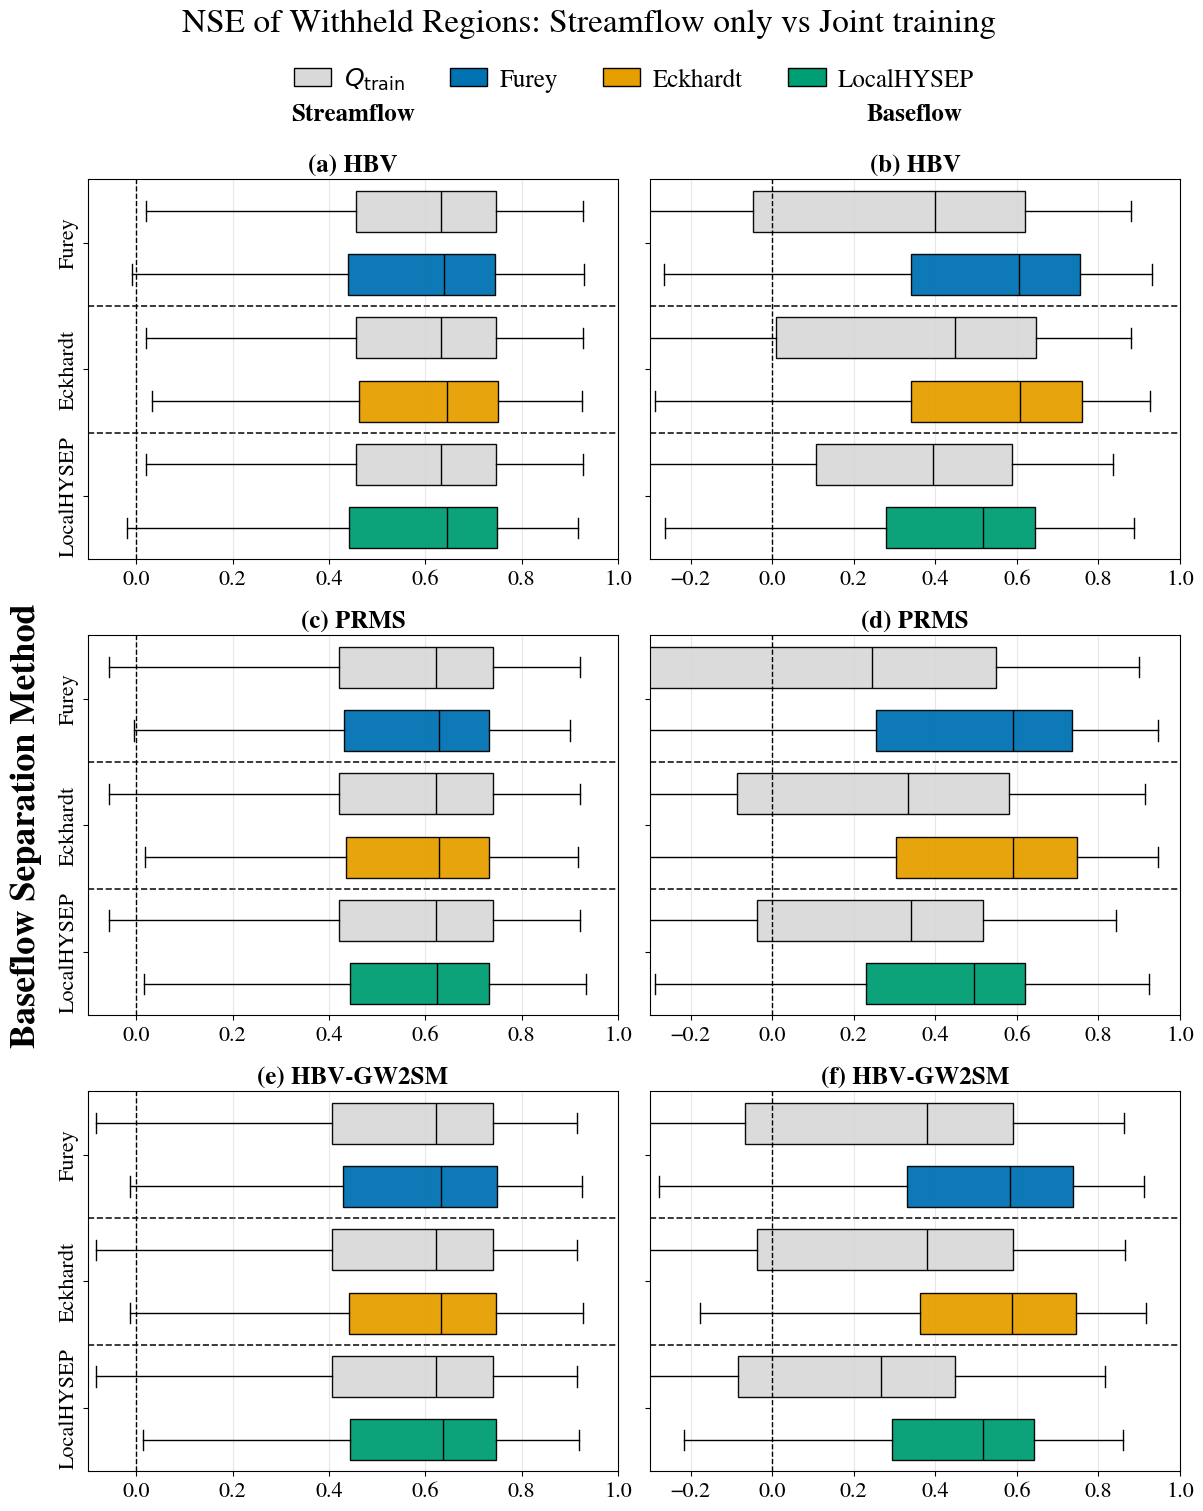

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'RMSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}

for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)

        # print(method,model)
        # print(table.columns)
        all_tables[(method, model)] = table.copy()

# ============================================================
# CREATE 3 x 2 BOXPLOT FIGURE
# Single-Objective above Multi-Objective
# ============================================================
# gray #D9D9D9
# Furey: blue #0072B2
# Eckhardt: orange #E69F00
# LocalHYSEP: bluish green #009E73
# Colors: lighter = Single, darker = Multi
method_colors = {
    'Furey': {
        'Single': '#D9D9D9',
        'Multi':  '#0072B2'
    },
    'Eckhardt': {
        'Single': '#D9D9D9',
        'Multi':  '#E69F00'
    },
    'LocalHYSEP': {
        'Single': '#D9D9D9',
        'Multi':  '#009E73'
    }
}

model_names = {
    'HBV': 'HBV',
    'marrmot_PRMS': 'PRMS',
    'HBV_capillary': 'HBV-GW2SM'
}

flow_col = 'NSE-Flow (Multi-Objective)'
baseflow_col = 'NSE-Baseflow (Multi-Objective)'

flow_single = 'NSE-Flow (Single-Objective)'
baseflow_single = 'NSE-Baseflow (Single-Objective)'

median_props = {
    'color': 'black',
    'linestyle': '-',
    'linewidth': 1
}

# ============================================================
# BOXPLOT POSITIONS
# ============================================================

# Each method has two boxes:
# Single-Objective above Multi-Objective

positions = [6, 5, 4, 3, 2, 1]

# Method labels centered between each pair
tick_positions = [5.5, 3.5, 1.5]

# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 17),
    # sharex=True,
    sharex=False
)

# ============================================================
# LOOP OVER MODELS
# ============================================================

for i, model in enumerate(models):

    # ========================================================
    # STREAMFLOW NSE
    # ========================================================

    flow_data = []
    flow_colors = []

    for method in methods:

        # Single-Objective values
        values_single = all_tables[(method, model)][flow_single].to_numpy()
        values_single = values_single[np.isfinite(values_single)]

        # Multi-Objective values
        values_multi = all_tables[(method, model)][flow_col].to_numpy()
        values_multi = values_multi[np.isfinite(values_multi)]

        # Append Single first, then Multi
        flow_data.extend([
            values_single,
            values_multi
        ])

        flow_colors.extend([
            method_colors[method]['Single'],
            method_colors[method]['Multi']
        ])

    # Create boxplots
    bp = axes[i, 0].boxplot(
        flow_data,
        positions=positions,
        vert=False,
        widths=0.65,
        patch_artist=True,
        showfliers=False,
        # whis=(5, 95),
        medianprops=median_props
    )
    lab0= ['(a)','(c)', '(e)']
    # axes[i,0].set_xlabel(lab0[i],fontsize=20)
    # Apply colors
    for patch, color in zip(bp['boxes'], flow_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.95)

    # Center method labels between Single and Multi
    axes[i, 0].set_yticks(tick_positions)
    axes[i, 0].set_yticklabels(methods)

    if i==0: # Titles and axes formatting 
        axes[i, 0].set_title( f'Streamflow\n \n{lab0[i]} {model_names[model]}', fontsize=18, fontweight='bold' ) 
    else: 
          axes[i, 0].set_title( f'{lab0[i]} {model_names[model]}', fontsize=18, fontweight='bold' )

    axes[i, 0].axvline(
        0,
        color='black',
        linestyle='--',
        linewidth=1
    )

    axes[i, 0].grid(
        axis='x',
        alpha=0.3
    )
    
    
    # ========================================================
    # BASEFLOW NSE
    # ========================================================

    baseflow_data = []
    baseflow_colors = []

    for method in methods:

        # Single-Objective values
        values_single = all_tables[(method, model)][baseflow_single].to_numpy()
        values_single = values_single[np.isfinite(values_single)]

        # Multi-Objective values
        values_multi = all_tables[(method, model)][baseflow_col].to_numpy()
        values_multi = values_multi[np.isfinite(values_multi)]

        # Append Single first, then Multi
        baseflow_data.extend([
            values_single,
            values_multi
        ])

        baseflow_colors.extend([
            method_colors[method]['Single'],
            method_colors[method]['Multi']
        ])

    # Create boxplots
    bp = axes[i, 1].boxplot(
        baseflow_data,
        positions=positions,
        vert=False,
        widths=0.65,
        patch_artist=True,
        showfliers=False,
        # whis=(5, 95),
        medianprops=median_props
    )

    # Apply colors
    for patch, color in zip(bp['boxes'], baseflow_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.95)

    # Center method labels between Single and Multi
    axes[i, 1].set_yticks(tick_positions)
    axes[i, 1].set_yticklabels(methods)


    lab1= ['(b)','(d)', '(f)']
    # axes[i,1].set_xlabel(lab1[i],fontsize=20)

    if i==0: # Titles and axes formatting 
        axes[i, 1].set_title( f'Baseflow\n \n{lab1[i]} {model_names[model]}', fontsize=18, fontweight='bold' ) 
    else: 
          axes[i, 1].set_title( f'{lab1[i]} {model_names[model]}', fontsize=18, fontweight='bold' )

    axes[i, 1].axvline(
        0,
        color='black',
        linestyle='--',
        linewidth=1
    )

    axes[i, 1].grid(
        axis='x',
        alpha=0.3
    )


    axes[i,0].set_xlim(-0.1,1)
    axes[i,1].set_xlim(-0.3,1)
    



    # ============================================================
    # DASHED LINES BETWEEN BASEFLOW SEPARATION METHODS
    # ============================================================

    for j in range(2):  # Streamflow and Baseflow columns

        ax = axes[i, j]

        # Draw separators between methods
        for k in range(len(methods) - 1):

            y_sep = (tick_positions[k] + tick_positions[k + 1]) / 2

            ax.axhline(
                y_sep,
                color='black',
                linestyle='--',
                linewidth=1.2,
                alpha=0.9,
                zorder=0
            )
    # ========================================================
    # Y-AXIS FORMATTING
    # ========================================================

    for j in range(2):
        axes[i, j].tick_params( 
            axis='y',
            pad=10
        )

        plt.setp(
            axes[i, j].get_yticklabels(),
            rotation=90,
            ha='center',
            va='center',
            fontsize=16,
        )

        plt.setp(
            axes[i, j].get_xticklabels(),
            # rotation=90,
            # ha='center',
            # va='center',
            fontsize=16,
        )

        axes[i, j].set_ylim(0.5, 6.5)

        axes[i, 1].set_yticklabels([])
# ============================================================
# COMMON LABELS
# ============================================================

# fig.supxlabel(
#     'Nash–Sutcliffe Efficiency (NSE)',
#     fontsize=24,
#     # fontweight='bold',
#     y=0.04
# )

fig.supylabel(
    'Baseflow Separation Method',
    fontsize=26,
    fontweight='bold',
    x=0.08
)

# ============================================================
# SPACING
# ============================================================

# plt.subplots_adjust(
#     left=0.14,
#     right=0.98,
#     bottom=0.13,
#     top=0.94,
#     wspace=0.12,
#     hspace=0.35
# )

plt.subplots_adjust(
    left=0.14,
    right=0.98,
    bottom=0.12,
    top=0.88,
    wspace=0.06,
    hspace=0.2
)

plt.suptitle("\t       NSE of Withheld Regions: Streamflow only vs Joint training",fontsize=24)#, fontweight='bold')


from matplotlib.patches import Patch

# ============================================================
# LEGEND
# ============================================================

legend_handles = [
    Patch(
        facecolor='#D9D9D9',
        edgecolor='black',
        label=r'$Q_{\mathrm{train}}$'
    ),
    Patch(
        facecolor='#0072B2',
        edgecolor='black',
        label='Furey'
    ),
    Patch(
        facecolor='#E69F00',
        edgecolor='black',
        label='Eckhardt'
    ),
    Patch(
        facecolor='#009E73',
        edgecolor='black',
        label='LocalHYSEP'
    )
]

fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.56, 0.96),
    ncol=4,
    fontsize=18,
    frameon=False,
    handlelength=1.5,
    columnspacing=1.8,
    handletextpad=0.5
)


# plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures/Spaced_{loss}_loss_Boxplots_standard_whiskers.jpg", dpi= 400)
plt.show()

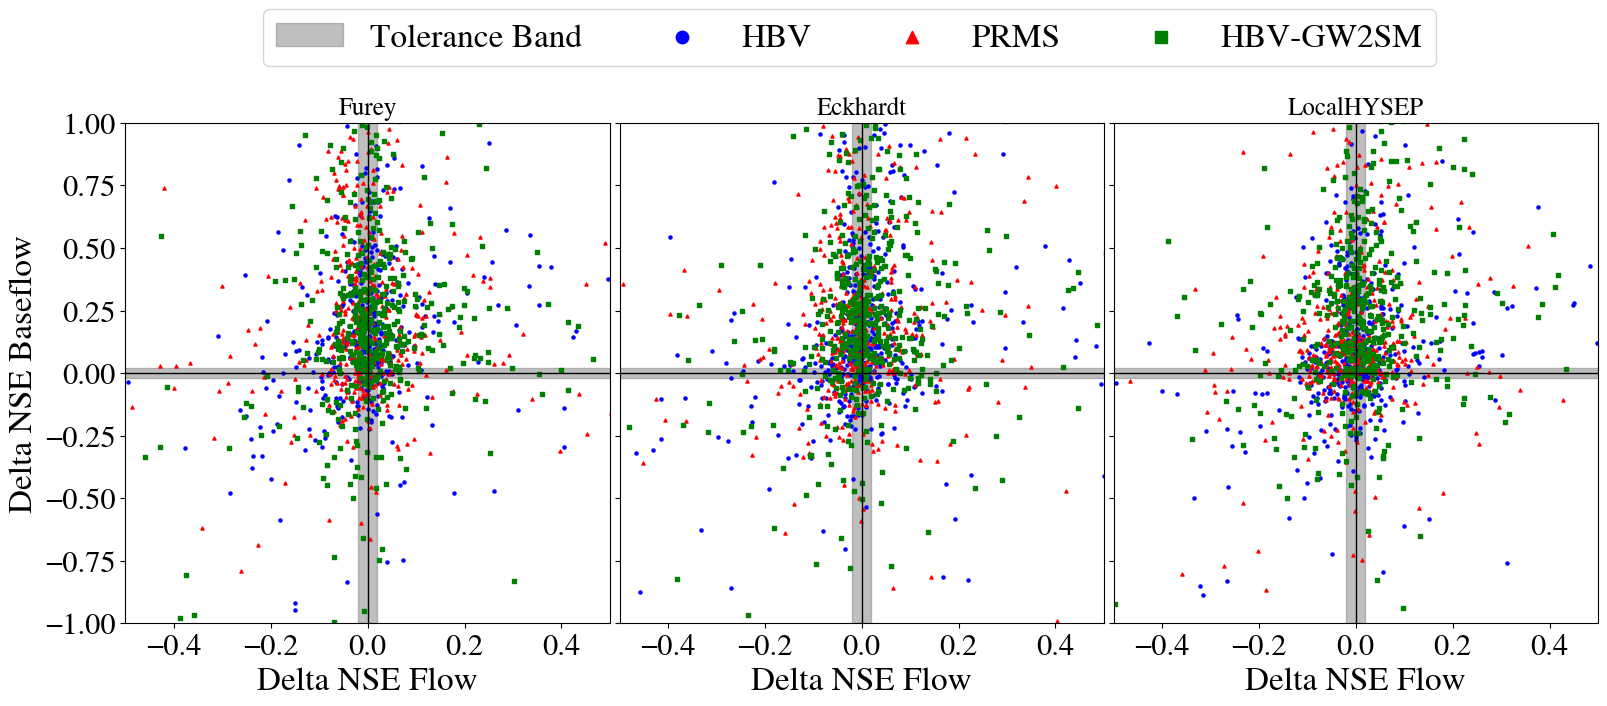

In [34]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'RMSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}
plt.figure(figsize=(19,6.5))

for i,method in enumerate(methods):
    tables = []
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSE-DeltaFlow']= table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']
        table['NSE-DeltaBaseflow']= table['NSE-Baseflow (Multi-Objective)'] - table['NSE-Baseflow (Single-Objective)']


        tables.append(table)
        # print(method,model)
        # print(table.columns)
        all_tables[(method, model)] = table.copy()

    plt.subplot(1,3,i+1)
    # Add shaded tolerance areas (alpha=0.5 gray)
    plt.axvspan(-0.02, 0.02, color="gray", alpha=0.5, label='Tolerance Band')
    plt.axhspan(-0.02, 0.02, color="gray", alpha=0.5)
    plt.axhline(0, color="black", linestyle="-", linewidth=1)
    plt.axvline(0, color="black", linestyle="-", linewidth=1)
    # plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    # plt.axvline(0, color="gray", linestyle="--", linewidth=1)
    plt.scatter(tables[0]['NSE-DeltaFlow'],tables[0]['NSE-DeltaBaseflow'], label=model_names[models[0]], marker='o', color= 'blue', s=5)
    plt.scatter(tables[1]['NSE-DeltaFlow'],tables[1]['NSE-DeltaBaseflow'], label=model_names[models[1]], marker='^', color= 'red', s=5)
    plt.scatter(tables[2]['NSE-DeltaFlow'],tables[2]['NSE-DeltaBaseflow'], label=model_names[models[2]], marker='s', color= 'green', s=5)
    plt.xlabel(f'Delta NSE Flow', fontsize= 24)
    plt.title(method, fontsize=18)
    if i==0:
        plt.ylabel('Delta NSE Baseflow', fontsize= 24)
        plt.yticks(fontsize=22)
    else:
        plt.tick_params(labelleft=False)
    plt.xlim(-0.5, 0.5)
    plt.ylim(-1, 1)

    plt.xticks(fontsize=22)
plt.subplots_adjust(wspace=0.02)
# Place legend at the top middle, arranged horizontally (3 columns)
plt.legend(loc="upper right", bbox_to_anchor=(0.7, 1.26), ncol=4, frameon=True, fontsize=24, markerscale=4.0)

# plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures/{loss}_losss_Flow_Baseflow_scatterplot.jpg", dpi= 400)
plt.show()

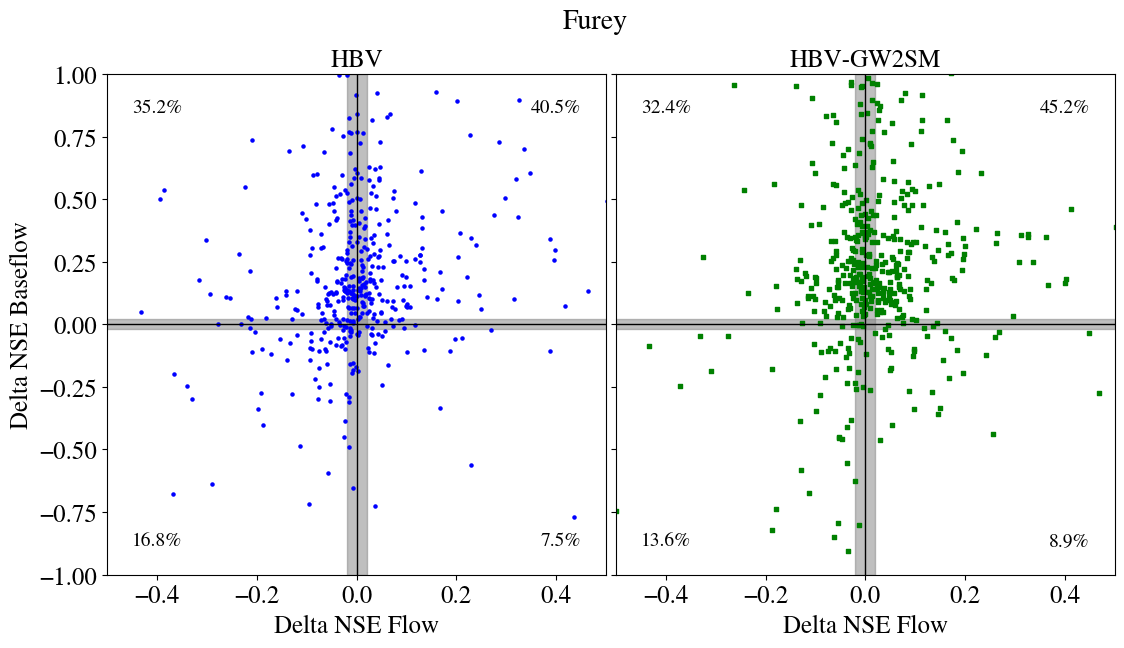

In [5]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'NSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']
methods=['Furey']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}

tables = []
for i,model in enumerate(models):
   
    for j,method in enumerate(methods):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSE-DeltaFlow']= table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']
        table['NSE-DeltaBaseflow']= table['NSE-Baseflow (Multi-Objective)'] - table['NSE-Baseflow (Single-Objective)']


        tables.append(table)
        # print(method,model)
        # print(table.columns)
        all_tables[(method, model)] = table.copy()

import numpy as np

plt.figure(figsize=(13, 6.5))

# Loop for the two subplots (index 0 for tables[0], index 1 for tables[2])
plot_configs = [(1, 0, "blue", "o"), (2, 2, "green", "s")]

for subplot_idx, table_idx, color, marker in plot_configs:
  plt.subplot(1, 2, subplot_idx)

  # Shaded tolerance areas & origin lines
  plt.axvspan(-0.02, 0.02, color="gray", alpha=0.5)
  plt.axhspan(-0.02, 0.02, color="gray", alpha=0.5)
  plt.axhline(0, color="black", linestyle="-", linewidth=1)
  plt.axvline(0, color="black", linestyle="-", linewidth=1)

  # Data
  x = tables[table_idx]["NSE-DeltaFlow"]
  y = tables[table_idx]["NSE-DeltaBaseflow"]

  plt.scatter(
      x,
      y,
      label=model_names[models[table_idx]],
      marker=marker,
      color=color,
      s=5,
  )

  # --- Calculate Quadrant Percentages ---
  total_points = len(x)
  if total_points > 0:
    # Quadrant 1: x > 0, y > 0 (Top-Right)
    q1 = np.sum((x > 0) & (y > 0)) / total_points * 100
    # Quadrant 2: x < 0, y > 0 (Top-Left)
    q2 = np.sum((x < 0) & (y > 0)) / total_points * 100
    # Quadrant 3: x < 0, y < 0 (Bottom-Left)
    q3 = np.sum((x < 0) & (y < 0)) / total_points * 100
    # Quadrant 4: x > 0, y < 0 (Bottom-Right)
    q4 = np.sum((x > 0) & (y < 0)) / total_points * 100

    # Display percentages as text in each corner
    # (x_pos, y_pos, text, horizontalalignment, verticalalignment)
    text_kwargs = dict(
        fontsize=14,
        color="black",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7),
    )

    plt.text(0.45, 0.9, f"{q1:.1f}%", ha="right", va="top", **text_kwargs)  # TR
    plt.text(
        -0.45, 0.9, f"{q2:.1f}%", ha="left", va="top", **text_kwargs
    )  # TL
    plt.text(
        -0.45, -0.9, f"{q3:.1f}%", ha="left", va="bottom", **text_kwargs
    )  # BL
    plt.text(
        0.45, -0.9, f"{q4:.1f}%", ha="right", va="bottom", **text_kwargs
    )  # BR

  # Plot styling
  plt.xlabel("Delta NSE Flow", fontsize=18)
  plt.title(model_names[models[table_idx]], fontsize=18)
  plt.xlim(-0.5, 0.5)
  plt.ylim(-1, 1)
  plt.xticks(fontsize=18)
  plt.yticks(fontsize=18)

  if subplot_idx == 1:
    plt.ylabel("Delta NSE Baseflow", fontsize=18)
  else:
    plt.tick_params(labelleft=False)

plt.subplots_adjust(wspace=0.02)
plt.suptitle("Furey", fontsize=20)
plt.show()

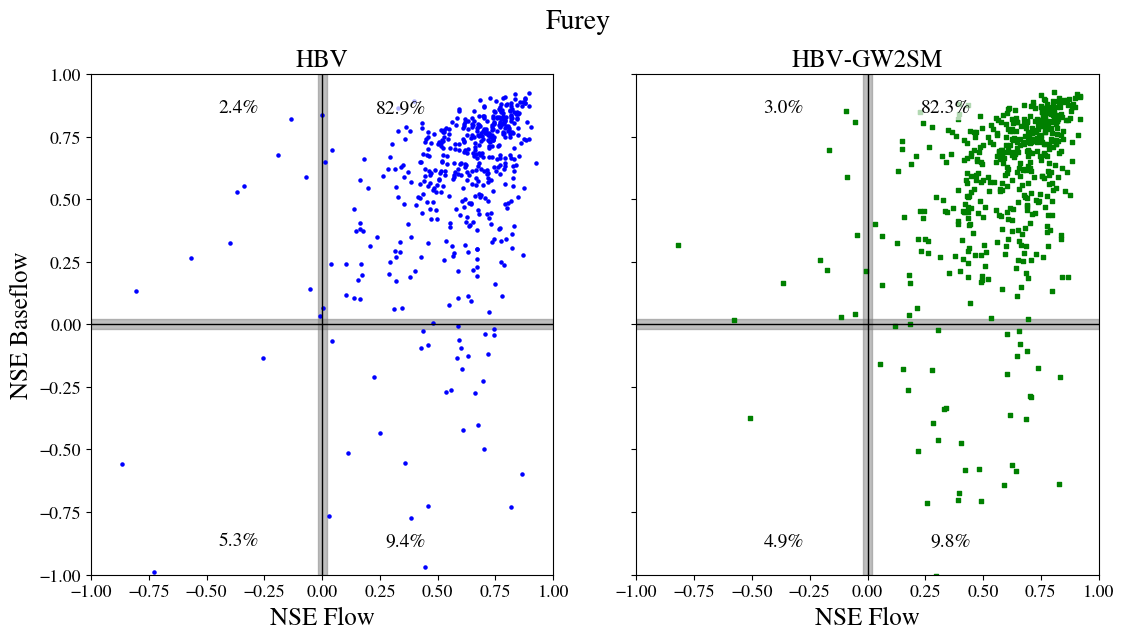

In [6]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'NSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']
methods=['Furey']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}

tables = []
for i,model in enumerate(models):
   
    for j,method in enumerate(methods):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSE-DeltaFlow']= table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']
        table['NSE-DeltaBaseflow']= table['NSE-Baseflow (Multi-Objective)'] - table['NSE-Baseflow (Single-Objective)']


        tables.append(table)
        # print(method,model)
        # print(table.columns)
        all_tables[(method, model)] = table.copy()

import numpy as np

plt.figure(figsize=(13, 6.5))

# Loop for the two subplots (index 0 for tables[0], index 1 for tables[2])
plot_configs = [(1, 0, "blue", "o"), (2, 2, "green", "s")]

for subplot_idx, table_idx, color, marker in plot_configs:
  plt.subplot(1, 2, subplot_idx)

  # Shaded tolerance areas & origin lines
  plt.axvspan(-0.02, 0.02, color="gray", alpha=0.5)
  plt.axhspan(-0.02, 0.02, color="gray", alpha=0.5)
  plt.axhline(0, color="black", linestyle="-", linewidth=1)
  plt.axvline(0, color="black", linestyle="-", linewidth=1)

  # Data
  x = tables[table_idx]["NSE-Flow (Multi-Objective)"]
  y = tables[table_idx]["NSE-Baseflow (Multi-Objective)"]

  plt.scatter(
      x,
      y,
      label=model_names[models[table_idx]],
      marker=marker,
      color=color,
      s=5,
  )

  # --- Calculate Quadrant Percentages ---
  total_points = len(x)
  if total_points > 0:
    # Quadrant 1: x > 0, y > 0 (Top-Right)
    q1 = np.sum((x > 0) & (y > 0)) / total_points * 100
    # Quadrant 2: x < 0, y > 0 (Top-Left)
    q2 = np.sum((x < 0) & (y > 0)) / total_points * 100
    # Quadrant 3: x < 0, y < 0 (Bottom-Left)
    q3 = np.sum((x < 0) & (y < 0)) / total_points * 100
    # Quadrant 4: x > 0, y < 0 (Bottom-Right)
    q4 = np.sum((x > 0) & (y < 0)) / total_points * 100

    # Display percentages as text in each corner
    # (x_pos, y_pos, text, horizontalalignment, verticalalignment)
    text_kwargs = dict(
        fontsize=14,
        color="black",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7),
    )

    plt.text(0.45, 0.9, f"{q1:.1f}%", ha="right", va="top", **text_kwargs)  # TR
    plt.text(
        -0.45, 0.9, f"{q2:.1f}%", ha="left", va="top", **text_kwargs
    )  # TL
    plt.text(
        -0.45, -0.9, f"{q3:.1f}%", ha="left", va="bottom", **text_kwargs
    )  # BL
    plt.text(
        0.45, -0.9, f"{q4:.1f}%", ha="right", va="bottom", **text_kwargs
    )  # BR

  # Plot styling
  plt.xlabel("NSE Flow", fontsize=18)
  plt.title(model_names[models[table_idx]], fontsize=18)
  plt.xlim(-1, 1)
  plt.ylim(-1, 1)
  plt.xticks(fontsize=13)
  plt.yticks(fontsize=13)

  if subplot_idx == 1:
    plt.ylabel("NSE Baseflow", fontsize=18)
  else:
    plt.tick_params(labelleft=False)

plt.subplots_adjust(wspace=0.18)
plt.suptitle("Furey", fontsize=20)
plt.show()

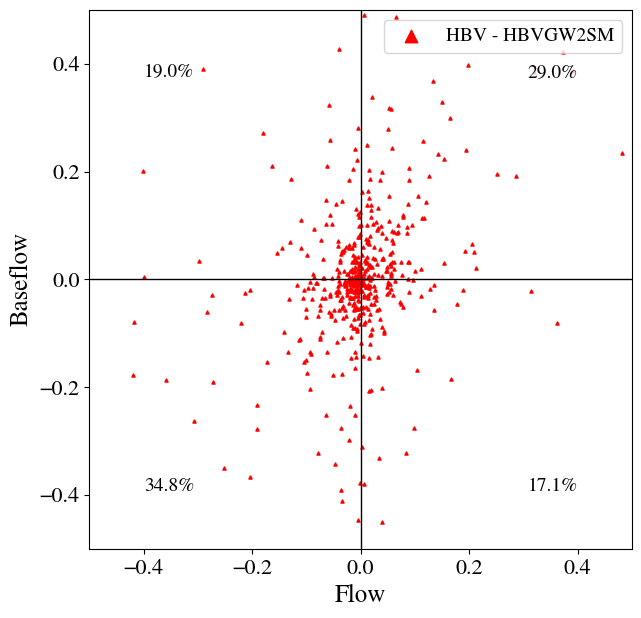

In [8]:
import pandas as pd
comp= pd.DataFrame()
comp['NSE-DeltaFlow']= tables[0]['NSE-Flow (Multi-Objective)']-tables[2]['NSE-Flow (Multi-Objective)']
comp['NSE-DeltaBaseflow']= tables[0]['NSE-Baseflow (Multi-Objective)']-tables[2]['NSE-Baseflow (Multi-Objective)']
comp

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Calculate total points and percentages
total_points = len(comp)

q1_pct = (
    len(
        comp[
            (comp['NSE-DeltaFlow'] > 0) & (comp['NSE-DeltaBaseflow'] > 0)
        ]
    )
    / total_points
    * 100
)
q2_pct = (
    len(
        comp[
            (comp['NSE-DeltaFlow'] < 0) & (comp['NSE-DeltaBaseflow'] > 0)
        ]
    )
    / total_points
    * 100
)
q3_pct = (
    len(
        comp[
            (comp['NSE-DeltaFlow'] < 0) & (comp['NSE-DeltaBaseflow'] < 0)
        ]
    )
    / total_points
    * 100
)
q4_pct = (
    len(
        comp[
            (comp['NSE-DeltaFlow'] > 0) & (comp['NSE-DeltaBaseflow'] < 0)
        ]
    )
    / total_points
    * 100
)

# Create figure
plt.figure(figsize=(7, 7))

plt.scatter(
    comp['NSE-DeltaFlow'],
    comp['NSE-DeltaBaseflow'],
    label='HBV - HBVGW2SM',
    marker='^',
    color='red',
    s=5,
)
plt.axhline(0, color='black', linestyle='-', linewidth=1)
plt.axvline(0, color='black', linestyle='-', linewidth=1)
plt.xlim(-0.5, 0.5)
plt.ylim(-0.5, 0.5)
plt.legend(markerscale=4, fontsize=14, loc='upper right')

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel('Flow', fontsize=18)
plt.ylabel('Baseflow', fontsize=18)

# Add percentage annotations to each quadrant
# Coordinates (x, y) can be adjusted based on your preference
plt.text(
    0.4,
    0.4,
    f'{q1_pct:.1f}%',
    fontsize=14,
    ha='right',
    va='top',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='none'),
)
plt.text(
    -0.4,
    0.4,
    f'{q2_pct:.1f}%',
    fontsize=14,
    ha='left',
    va='top',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='none'),
)
plt.text(
    -0.4,
    -0.4,
    f'{q3_pct:.1f}%',
    fontsize=14,
    ha='left',
    va='bottom',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='none'),
)
plt.text(
    0.4,
    -0.4,
    f'{q4_pct:.1f}%',
    fontsize=14,
    ha='right',
    va='bottom',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='none'),
)

plt.show()

HUC2 CRS before assignment: None
HUC2 bounds before transformation:
[-7783576.02289802  2187575.63815253  3619690.05690435 10257816.27458091]
HUC2 CRS after assignment: EPSG:26915
HUC2 CRS after transformation: EPSG:4326
HUC2 bounds after transformation:
[-179.96928239   17.67456073  179.91556688   71.39676244]

HUC2 columns:
['HUC2', 'COUNT', 'REG_NAME', 'ACRES', 'geometry']

Using HUC2 column: HUC2

HUC2 codes found:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']

The following HUC2 regions were not assigned:
['19', '20', '21']

PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.2193

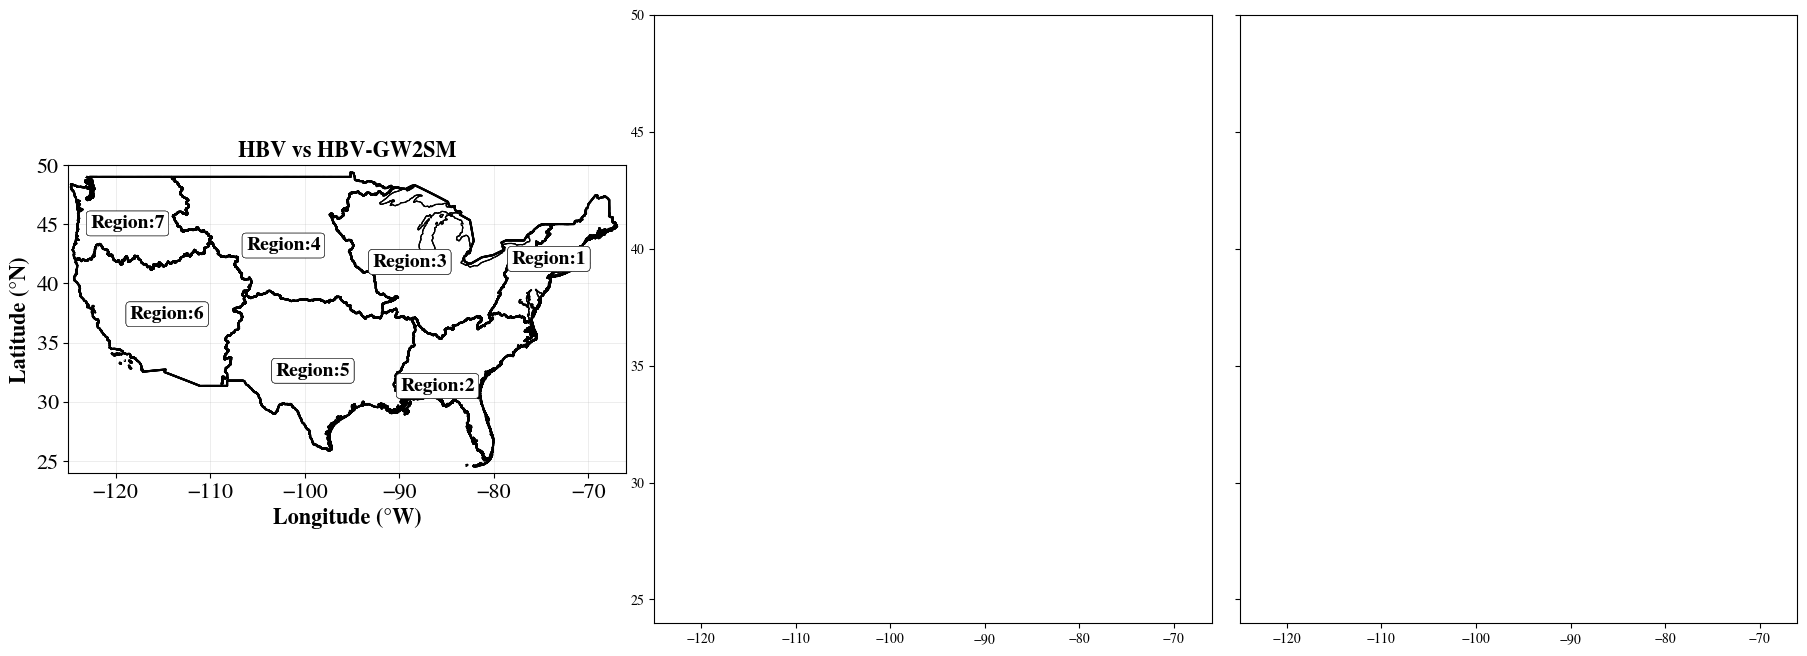

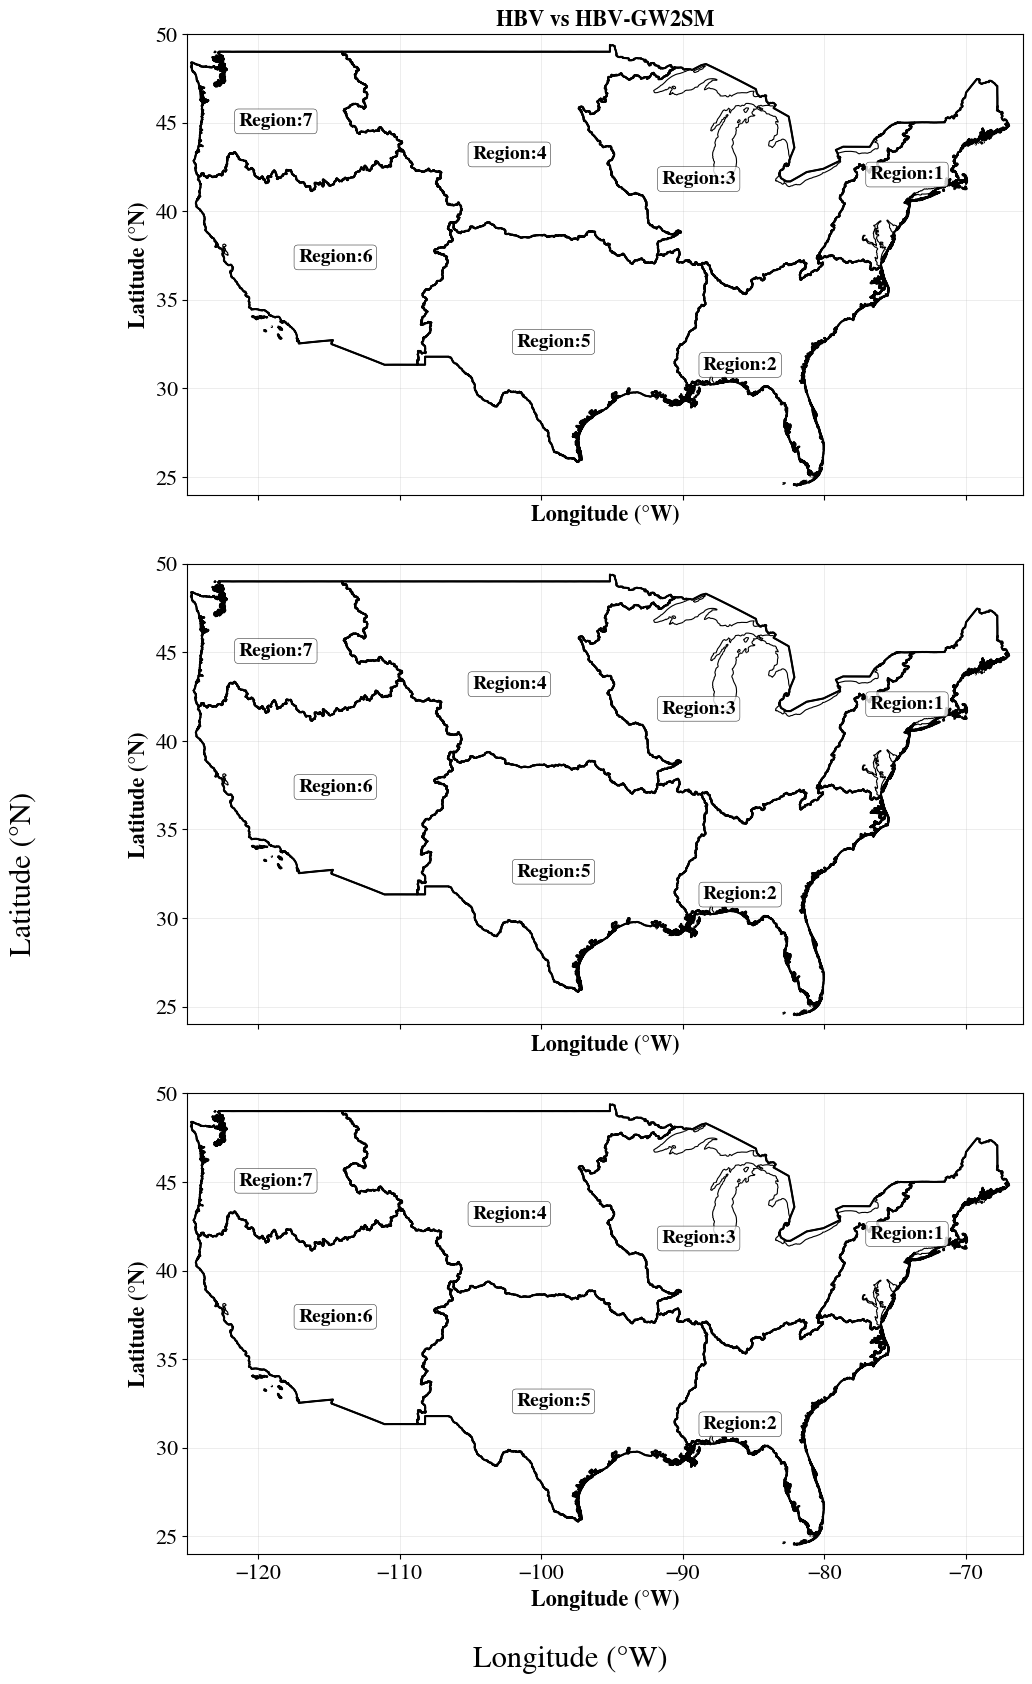

In [4]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# ============================================================
# FUNCTION TO PLOT PUR REGIONS AND REGION NUMBERS
# ============================================================
loss= 'NSE'

def add_pur_regions(ax, gdf_pur_regions):

    # Plot PUR region boundaries
    gdf_pur_regions.boundary.plot(
        ax=ax,
        edgecolor="black",
        linewidth=1.5,
        zorder=3
    )

    # Add region numbers
    for _, row in gdf_pur_regions.iterrows():

        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"Region:{int(row['PUR_region'])}",
            fontsize=14,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )


plt.rcParams['font.family']= 'Nimbus Roman'

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)


# ============================================================
# PUR REGION DEFINITION FROM FENG ET AL.
# ============================================================

pur_groups = {
    1: ['01', '02'],
    2: ['03', '06'],
    3: ['04', '05', '07'],
    4: ['09', '10'],
    5: ['08', '11', '12', '13'],
    6: ['14', '15', '16', '18'],
    7: ['17']
}

# [ [1,2], [3,6], [4,5,7], [9,10], [8,11,12,13], [14,15,16,18], [17] ]

# ------------------------------------------------------------
# Make sure HUC2 codes are strings with leading zero
# ------------------------------------------------------------

gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")

print("HUC2 CRS before assignment:", gdf_huc2.crs)
print("HUC2 bounds before transformation:")
print(gdf_huc2.total_bounds)
gdf_huc2 = gdf_huc2.set_crs(
    "EPSG:26915"
)

print("HUC2 CRS after assignment:", gdf_huc2.crs)


# ============================================================
# TRANSFORM HUC2 TO WGS84
# ============================================================

gdf_huc2 = gdf_huc2.to_crs(
    "EPSG:4326"
)

print("HUC2 CRS after transformation:", gdf_huc2.crs)
print("HUC2 bounds after transformation:")
print(gdf_huc2.total_bounds)


# ============================================================
# CHECK HUC2 COLUMNS
# ============================================================

print("\nHUC2 columns:")
print(gdf_huc2.columns.tolist())


possible_huc_columns = [
    "HUC2",
    "HUC_2",
    "HUC2_CODE",
    "HUC_02",
    "HUC_02_",
    "HUC2_",
    "HUC"
]

huc_column = None

for col in possible_huc_columns:

    if col in gdf_huc2.columns:
        huc_column = col
        break

if huc_column is None:

    raise ValueError(
        "\nCould not identify the HUC2 column.\n"
        "Available columns are:\n"
        + str(gdf_huc2.columns.tolist())
    )

print("\nUsing HUC2 column:", huc_column)


# ============================================================
# STANDARDIZE HUC2 CODES
# ============================================================

gdf_huc2["HUC2_CODE"] = (
    gdf_huc2[huc_column]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

print("\nHUC2 codes found:")
print(
    sorted(
        gdf_huc2["HUC2_CODE"].unique()
    )
)


# ============================================================
# CREATE HUC2 -> PUR REGION LOOKUP
# ============================================================

huc_to_region = {}

for region, hucs in pur_groups.items():

    for huc in hucs:

        huc_to_region[huc] = region


# ============================================================
# ASSIGN PUR REGION
# ============================================================

gdf_huc2["PUR_region"] = (
    gdf_huc2["HUC2_CODE"]
    .map(huc_to_region)
)


# Check whether any HUC2 was not assigned
unassigned = gdf_huc2[
    gdf_huc2["PUR_region"].isna()
]

if len(unassigned) > 0:

    print("\nWARNING:")
    print("The following HUC2 regions were not assigned:")
    print(
        unassigned["HUC2_CODE"]
        .tolist()
    )


# ============================================================
# KEEP PUR REGIONS
# ============================================================

gdf_pur = gdf_huc2.dropna(
    subset=["PUR_region"]
).copy()

gdf_pur["PUR_region"] = (
    gdf_pur["PUR_region"]
    .astype(int)
)


# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)


# ============================================================
# CREATE BASIN POINTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING BASIN POINTS")
print("=" * 70)


## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
# models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']
models= ['HBV']



if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

# ============================================================
# CREATE BOTH 3 x 1 FIGURES BEFORE THE LOOPS
# ============================================================

fig_flow, axes_flow = plt.subplots(
    1, 3,
    figsize=(19, 8),
    sharex=True,
    sharey=True
)

fig_baseflow, axes_baseflow = plt.subplots(
    3, 1,
    figsize=(14, 20),
    sharex=True,
    sharey=True
)

scatter_flow = None
scatter_baseflow = None

# ============================================================
# YOUR 3 x 1 LOOPS
# ============================================================


for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/HBV_capillary/{region}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/HBV_capillary/{region}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)


        # ax = axes_flow[i, j]
        ax = axes_flow[0]

        # CONUS boundary
        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )

        
        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        gdf_pur_regions.boundary.plot(
                    ax=ax,
                    edgecolor="black",
                    linewidth=1.2,
                    zorder=3
                )
        if i == 0:
            # --------------------------------------------
            # Subplot title
            # --------------------------------------------
            ax.set_title(
                            f"{model_name} vs HBV-GW2SM",
                            fontsize=16,
                            fontweight='bold'
                        )
            # ax.set_title(
            #     f"{method} | {model_name}",
            #     fontsize=13,
            #     fontweight='bold'
            # )

        if j== 0:

            ax.set_ylabel(f"Latitude (°N)",
                                                fontsize=16,
                                                fontweight='bold')
            ax.set_xlabel(f"Longitude (°W)",
                                                fontsize=16,
                                                fontweight='bold')



        # --------------------------------------------
        # Map limits
        # --------------------------------------------

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        # --------------------------------------------
        # Grid
        # --------------------------------------------

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )

        ax= axes_flow[1]
        ax.tick_params(
                    axis='both',
                    labelleft='False'
                )
        # ====================================================
        # FIGURE 2:
        # DELTA BASEFLOW NSE
        # ====================================================

        # ax = axes_baseflow[i, j]
        ax = axes_baseflow[i]

        # --------------------------------------------
        # CONUS boundary
        # --------------------------------------------

        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        # --------------------------------------------
        # PUR Region boundaries
        # --------------------------------------------

        gdf_pur_regions.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=1.2,
            zorder=3
        )

        

        if i == 0:
                    # --------------------------------------------
                    # Subplot title
                    # --------------------------------------------
                    ax.set_title(
                                    f"{model_name} vs HBV-GW2SM",
                                    fontsize=16,
                                    fontweight='bold'
                                )
                    # ax.set_title(
                    #     f"{method} | {model_name}",
                    #     fontsize=13,
                    #     fontweight='bold'
                    # )
        
        if j== 0:
        
                    ax.set_ylabel(f"Latitude (°N)",
                                    fontsize=16,
                                    fontweight='bold')
                    ax.set_xlabel(f"Longitude (°W)",
                                    fontsize=16,
                                    fontweight='bold')
        

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )

        print(i, j, method, model)


# ============================================================
# FIGURE 1 FORMATTING
# DELTA FLOW NSE
# ============================================================

# fig_flow.suptitle(
#     "Change in Streamflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


# ------------------------------------------------------------
# Shared X/Y labels
# ------------------------------------------------------------

# fig_flow.supxlabel(
#     "Longitude (°W)",
#     fontsize=22,
#     y=0.1
# )

# fig_flow.supylabel(
#     "Latitude (°N)",
#     fontsize=22,
#     x=0.1
# )


# ------------------------------------------------------------
# Make room for colorbar
# ------------------------------------------------------------

fig_flow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ============================================================
# FIGURE 2 FORMATTING
# DELTA BASEFLOW NSE
# ============================================================

# fig_baseflow.suptitle(
#     "Change in Baseflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


fig_baseflow.supxlabel(
    "Longitude (°W)",
    fontsize=22,
    y=0.1
)

fig_baseflow.supylabel(
    "Latitude (°N)",
    fontsize=22,
    x=0.1
)


fig_baseflow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ============================================================
# SHOW ONLY AFTER ALL 9 SUBPLOTS HAVE BEEN CREATED
# ============================================================
# output_dir = "/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures/"

# fig_flow.savefig(
#     f"{output_dir}/Delta_Flow_NSE_HBV_vs_HBVgw2sm.jpg",
#     dpi=400,
#     bbox_inches="tight")

# fig_baseflow.savefig(
#     f"{output_dir}/Delta_Baseflow_NSE_HBV_vs_HBVgw2sm.jpg",
#     dpi=400,
#     bbox_inches="tight")

plt.show()


PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.21938 26.01343, -97.2179 2...
5           6  MULTIPOLYGON (((-119.55325 33.23724, -119.556 ...
6           7  MULTIPOLYGON (((-123.95246 45.54629, -123.9488...


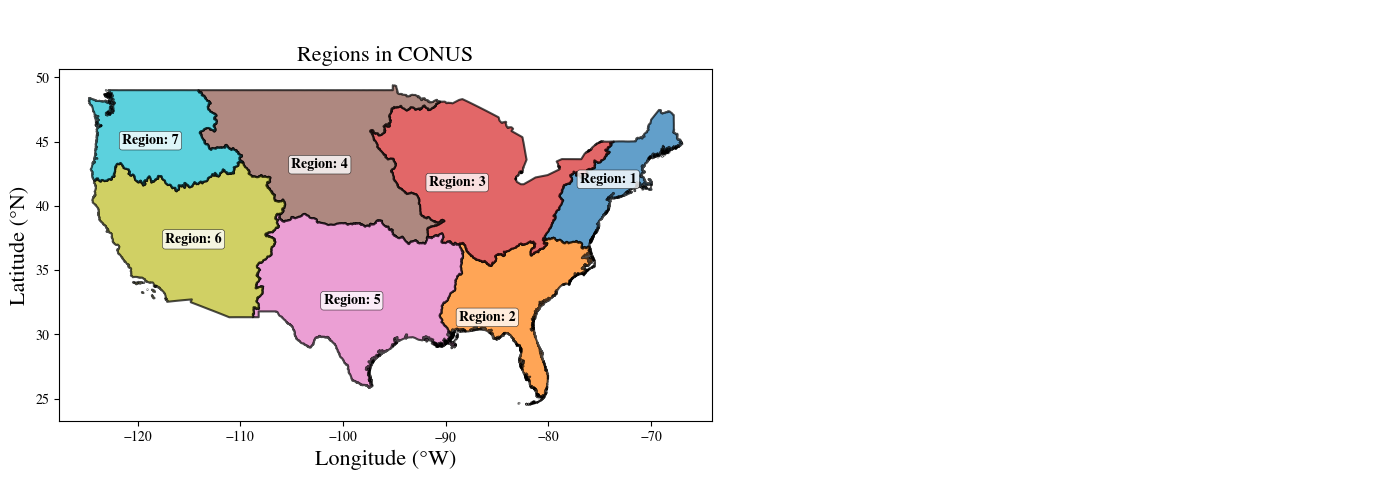

In [12]:
import matplotlib.pyplot as plt

# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)



def add_pur_regions(ax, gdf_pur_regions):
    # Plot filled PUR regions with a distinct color for each region
    gdf_pur_regions.plot(
        ax=ax,
        column='PUR_region',
        cmap='tab10',          # Qualitative colormap for distinct region colors
        edgecolor="black",
        linewidth=1.5,
        zorder=3,
        alpha=0.7              # Optional transparency so labels are easy to read
    )

    # Add region numbers using ax.text so they bind to the correct subplot
    for _, row in gdf_pur_regions.iterrows():
        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"Region: {int(row['PUR_region'])}",
            fontsize=10,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )

# Create a figure with 3 subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot on the first axis
add_pur_regions(axes[0], gdf_pur_regions)
axes[0].set_title("Regions in CONUS", fontsize=16)
axes[0].set_xlabel("Longitude (°W)", fontsize=16)
axes[0].set_ylabel("Latitude (°N)", fontsize=16)

# Leave the next two subplots blank and hide their frames for a clean look
axes[1].axis('off')
# axes[2].axis('off')

plt.tight_layout()
plt.show()


PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.21938 26.01343, -97.2179 2...
5           6  MULTIPOLYGON (((-119.55325 33.23724, -119.556 ...
6           7  MULTIPOLYGON (((-123.95246 45.54629, -123.9488...


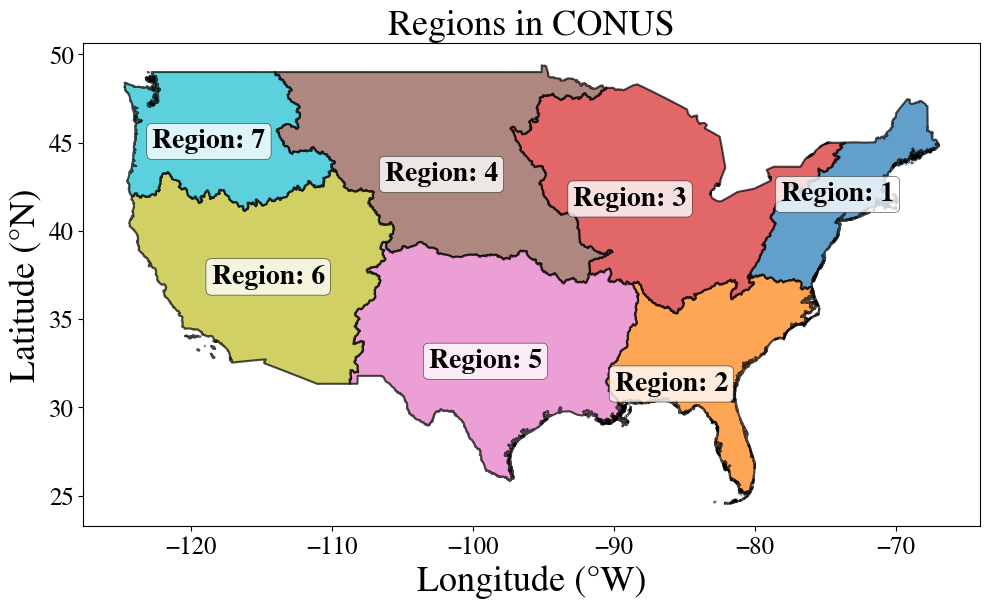

In [17]:
import matplotlib.pyplot as plt

# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = gdf_pur.dissolve(by="PUR_region").reset_index()

print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(gdf_pur_regions[["PUR_region", "geometry"]])


def add_pur_regions(ax, gdf_pur_regions):
  # Plot filled PUR regions with a distinct color for each region
  gdf_pur_regions.plot(
      ax=ax,
      column="PUR_region",
      cmap="tab10",  # Qualitative colormap for distinct region colors
      edgecolor="black",
      linewidth=1.5,
      zorder=3,
      alpha=0.7,  # Optional transparency so labels are easy to read
  )

  # Add region numbers using ax.text so they bind to the correct axis
  for _, row in gdf_pur_regions.iterrows():
    label_point = row.geometry.representative_point()

    ax.text(
        label_point.x,
        label_point.y,
        f"Region: {int(row['PUR_region'])}",
        fontsize=20,
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        zorder=5,
        bbox=dict(
            facecolor="white",
            edgecolor="black",
            linewidth=0.4,
            alpha=0.8,
            boxstyle="round,pad=0.2",
        ),
    )


# Create a single figure and axis
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the regions
add_pur_regions(ax, gdf_pur_regions)
ax.set_title("Regions in CONUS", fontsize=26)
ax.set_xlabel("Longitude (°W)", fontsize=26)
ax.set_ylabel("Latitude (°N)", fontsize=26)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
plt.savefig("/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures_NSE/PUR_REGIONS.jpg", dpi=400)
plt.show()

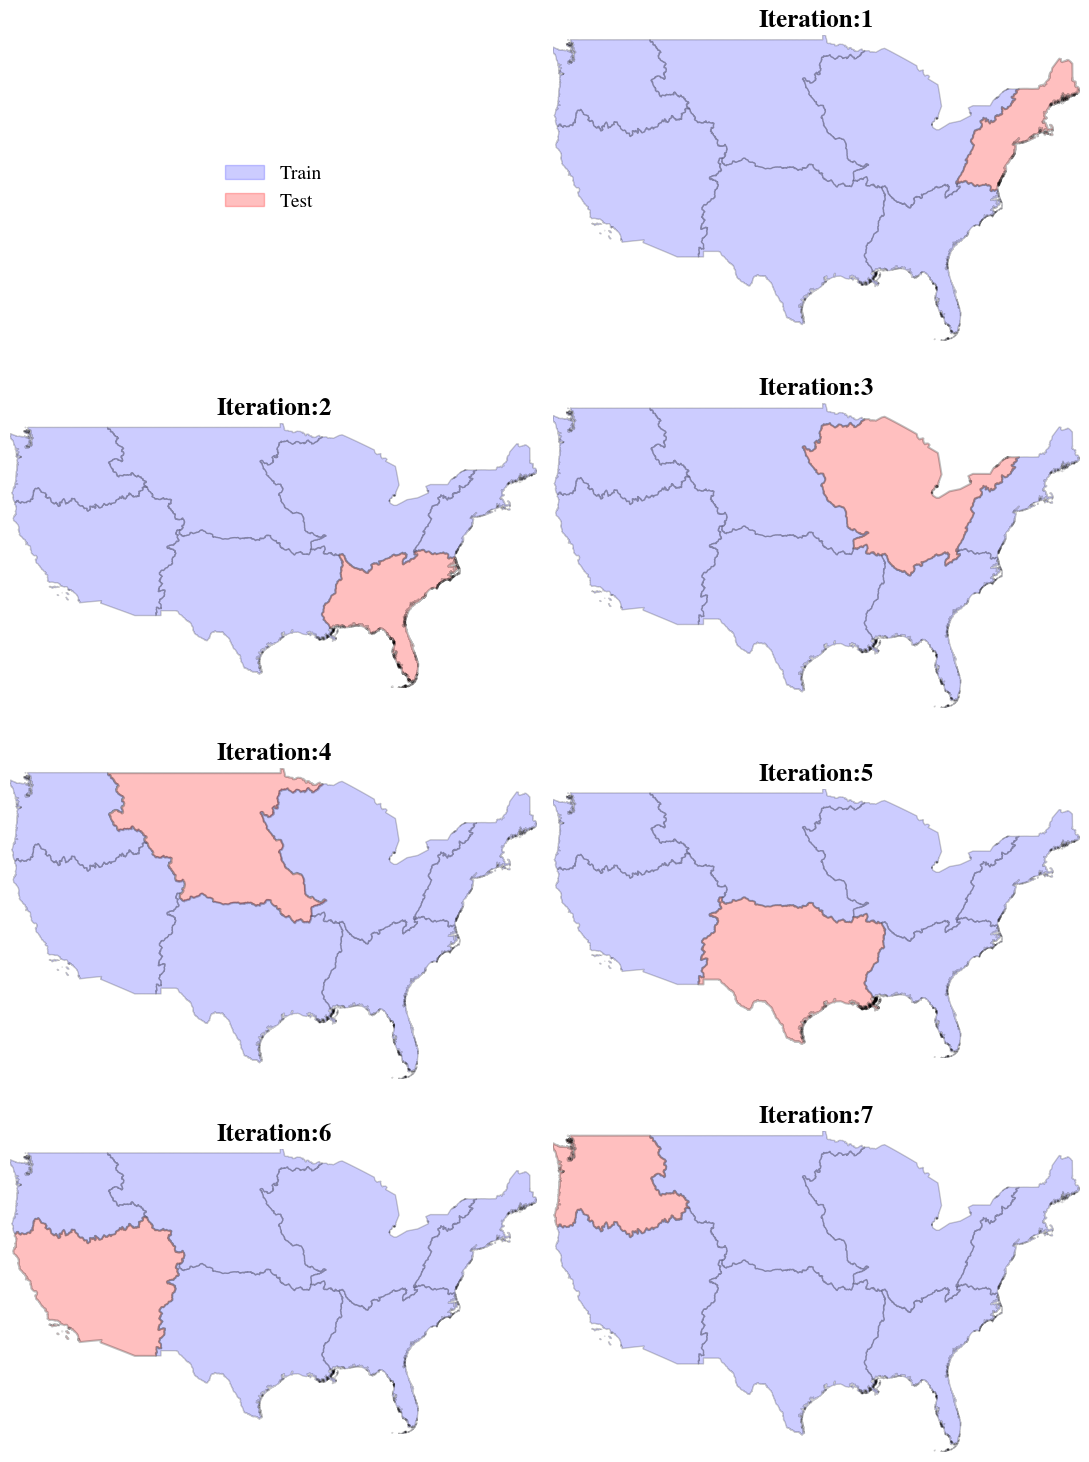

In [43]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import geopandas as gpd

# Limit to the first 7 regions (or however many you need)
num_regions = min(len(gdf_pur_regions), 7)

# Get the global bounding box of the entire dataset so all maps match perfectly
minx, miny, maxx, maxy = gdf_pur_regions.total_bounds

# Create a grid of subplots (4 rows, 2 columns = 8 total slots)
fig, axes = plt.subplots(4, 2, figsize=(11, 15))
axes = axes.flatten()  # Flatten the 2D array of axes into a 1D list

# 1. Place the legend in the very first slot (axes[0])
train_patch = mpatches.Patch(color='blue', alpha=0.2, label='Train')
test_patch = mpatches.Patch(color='red', alpha=0.25, label='Test')

axes[0].legend(
    handles=[train_patch, test_patch], 
    loc='center', 
    fontsize=14, 
    frameon=False
)
axes[0].axis('off')  # Hide the box border for the legend slot

# 2. Loop through the regions and plot them starting from index 1 (axes[1] to axes[7])
for i in range(num_regions):
    ax = axes[i + 1]  # Shift by +1 to leave axes[0] free for the legend
    target_idx = gdf_pur_regions.index[i]
    
    # Plot all OTHER regions in blue (Train)
    others = gdf_pur_regions.drop(target_idx)
    others.plot(
        ax=ax,
        color='blue',
        edgecolor='black',
        linewidth=1.0,
        alpha=0.2,
        zorder=2
    )
    
    # Plot the TARGET region in red (Test)
    target = gdf_pur_regions.loc[[target_idx]]
    target.plot(
        ax=ax,
        color='red',
        edgecolor='black',
        linewidth=1.5,
        alpha=0.25,
        zorder=3
    )
    
    # Force all subplots to share the exact same map boundaries and scale
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    
    # Title and cleanup
    region_num = int(target['PUR_region'].values[0])
    ax.set_title(f"Iteration:{region_num}", fontsize=18, fontweight='bold')
    ax.axis('off')

# Hide any remaining unused subplots
for j in range(num_regions + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [51]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'NSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Eckhardt','Furey', 'LocalHYSEP']
# methods=['Eckhardt']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

# models= ['HBV']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}
summary_metrics = []
tables = []
for i,model in enumerate(models):
   
    for j,method in enumerate(methods):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,8):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                        f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                    )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSE-DeltaFlow']= table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']
        table['NSE-DeltaBaseflow']= table['NSE-Baseflow (Multi-Objective)'] - table['NSE-Baseflow (Single-Objective)']
        print(model, method)
        # display(table)

        # Number of entries
        n = len(table)

        # -----------------------------------------------------
        # Median changes
        # -----------------------------------------------------
        median_delta_flow = table['NSE-DeltaFlow'].median()
        median_delta_baseflow = table['NSE-DeltaBaseflow'].median()

        # -----------------------------------------------------
        # Four possible sign combinations
        # -----------------------------------------------------

        # Both improve
        both_positive = (
            (table['NSE-DeltaFlow'] > 0) &
            (table['NSE-DeltaBaseflow'] > 0)
        ).mean() * 100

        # Flow improves, Baseflow decreases
        flow_pos_base_neg = (
            (table['NSE-DeltaFlow'] > 0) &
            (table['NSE-DeltaBaseflow'] < 0)
        ).mean() * 100

        # Baseflow improves, Flow decreases
        base_pos_flow_neg = (
            (table['NSE-DeltaBaseflow'] > 0) &
            (table['NSE-DeltaFlow'] < 0)
        ).mean() * 100

        # Both decrease
        both_negative = (
            (table['NSE-DeltaFlow'] < 0) &
            (table['NSE-DeltaBaseflow'] < 0)
        ).mean() * 100

        # -----------------------------------------------------
        # Target met
        # Baseflow improvement > 0.02
        # while Streamflow degradation is no worse than -0.02
        # -----------------------------------------------------
        target_met = (
            (table['NSE-DeltaBaseflow'] > 0.02) &
            (table['NSE-DeltaFlow'] >= -0.02)
        ).mean() * 100

        # -----------------------------------------------------
        # Streamflow loss
        # -----------------------------------------------------
        streamflow_loss = (
            table['NSE-DeltaFlow'] < 0
        ).mean() * 100


        # Flow improves
        flow_pos = (
                    (table['NSE-DeltaFlow'] > 0)
                ).mean() * 100

        tol = 0.02
        d_b, d_q = table['NSE-DeltaBaseflow'], table['NSE-DeltaFlow']
        
        # target_met      = ((d_b > tol) & (d_q >= -tol)).mean() * 100
        # baseflow_gain   = (d_b > tol).mean() * 100      # meaningful baseflow improvement
        # baseflow_loss   = (d_b < -tol).mean() * 100     # meaningful baseflow degradation
        streamflow_loss = (d_q < -tol).mean() * 100     # meaningful streamflow degradation
        streamflow_gain = (d_q > tol).mean() * 100
        
        from scipy.stats import wilcoxon
        p_b = wilcoxon(d_b.dropna()).pvalue
        p_q = wilcoxon(d_q.dropna()).pvalue
        # -----------------------------------------------------
        # Save summary
        # -----------------------------------------------------

        def format_pvalue(p):
            if p < 0.001:
                return f"{p:.2e}"  # Scientific notation for tiny values
            else:
                return f"{p:.3f}"  # Standard 3 decimal places for normal values
            
        summary_metrics.append({
            'Model': model,
            'Method': method,
            'Median NSE-DeltaFlow': f"{median_delta_flow:.3f}",
            'Median NSE-DeltaBaseflow': f"{median_delta_baseflow:.3f}",
            'Both Positive (%)': f"{both_positive:.3f}",
            'Flow + / Baseflow - (%)': f"{flow_pos_base_neg:.3f}",
            'Baseflow + / Flow - (%)': f"{base_pos_flow_neg:.3f}",
            'Both Negative (%)': f"{both_negative:.3f}",
            'Target Met (%)': f"{target_met:.3f}",
            'Streamflow Loss (%)': f"{streamflow_loss:.3f}",
            'Streamflow Gain (%)': f"{streamflow_gain:.3f}",
            'P_B': format_pvalue(p_b),
            'P_Q': format_pvalue(p_q),
        })
# ============================================================
# FINAL SUMMARY TABLE
# ============================================================

summary_table = pd.DataFrame(summary_metrics)

# Round values for display
summary_table = summary_table.round({
    'Median NSE-DeltaFlow': 3,
    'Median NSE-DeltaBaseflow': 3,
    'Both Positive (%)': 1,
    'Flow + / Baseflow - (%)': 1,
    'Baseflow + / Flow - (%)': 1,
    'Both Negative (%)': 1,
    'Target Met (%)': 1,
    'Streamflow Loss (%)': 1
})

display(summary_table)
summary_table.to_csv("/home/s0shar47/scratch/somemetrics.csv", index=False)

HBV Eckhardt
HBV Furey
HBV LocalHYSEP
marrmot_PRMS Eckhardt
marrmot_PRMS Furey
marrmot_PRMS LocalHYSEP
HBV_capillary Eckhardt
HBV_capillary Furey
HBV_capillary LocalHYSEP


,Model,Method,Median NSE-DeltaFlow,Median NSE-DeltaBaseflow,Both Positive (%),Flow + / Baseflow - (%),Baseflow + / Flow - (%),Both Negative (%),Target Met (%),Streamflow Loss (%),Streamflow Gain (%),P_B,P_Q
0,HBV,Eckhardt,-0.002,0.143,42.938,5.838,33.522,17.702,51.224,38.983,35.593,9.96e-31,0.990
1,HBV,Furey,-0.006,0.163,40.490,7.533,35.217,16.761,50.471,38.041,36.911,1.74e-32,0.998
2,HBV,LocalHYSEP,-0.006,0.065,34.275,10.358,31.262,23.917,41.996,41.055,33.522,4.64e-13,0.186
3,marrmot_PRMS,Eckhardt,-0.011,0.210,36.347,8.286,39.736,15.631,44.256,44.821,36.158,2.06e-33,0.259
4,marrmot_PRMS,Furey,-0.011,0.284,38.418,6.591,40.678,14.313,48.211,42.373,35.970,3.54e-42,0.359
5,marrmot_PRMS,LocalHYSEP,-0.013,0.150,33.522,8.851,39.925,17.514,40.866,46.516,35.217,5.30e-26,0.100
6,HBV_capillary,Eckhardt,0.012,0.212,46.893,8.663,30.132,14.313,56.309,29.755,45.763,1.60e-26,2.22e-06
7,HBV_capillary,Furey,0.009,0.202,45.198,8.851,32.392,13.559,55.179,33.145,45.009,2.27e-29,1.93e-04
8,HBV_capillary,LocalHYSEP,0.010,0.230,41.996,12.053,33.145,12.618,51.601,32.203,45.763,2.38e-28,8.32e-05


In [29]:
table

tol = 0.02
d_b, d_q = table['NSE-DeltaBaseflow'], table['NSE-DeltaFlow']
 
target_met      = ((d_b > tol) & (d_q >= -tol)).mean() * 100
baseflow_gain   = (d_b > tol).mean() * 100      # meaningful baseflow improvement
baseflow_loss   = (d_b < -tol).mean() * 100     # meaningful baseflow degradation
streamflow_loss = (d_q < -tol).mean() * 100     # meaningful streamflow degradation
streamflow_gain = (d_q > tol).mean() * 100
 
from scipy.stats import wilcoxon
p_b = wilcoxon(d_b.dropna()).pvalue
p_q = wilcoxon(d_q.dropna()).pvalue

In [35]:
# Check for exact zeros or NaNs
print((table['NSE-DeltaFlow'] == 0).sum())
print(table['NSE-DeltaFlow'].isna().sum())

0
0


In [41]:
 # Flow improves
flow_pos = ((table['NSE-DeltaFlow'] > 0)).mean() * 100

flow_pos

np.float64(54.23728813559322)

In [42]:
streamflow_loss = (table['NSE-DeltaFlow'] < 0).mean() * 100
streamflow_loss

np.float64(45.76271186440678)